
# Telecom Customer Churn Analysis & Predictive Retention Strategy

## Project Overview
This project analyzes customer data from a telecommunications company to identify patterns associated with customer churn and develop a data-driven customer retention strategy.

By combining customer profile information, usage behavior, revenue metrics, and service interactions, we aim to uncover actionable business insights and develop machine learning models capable of identifying customers at risk of churn.

## Business Objective
- Understand customer behavior and churn patterns.
- Identify key factors associated with customer attrition.
- Develop predictive models to estimate customer churn risk.
- Translate analytical findings into actionable customer retention strategies.
- Evaluate the potential business value of a proactive retention program.

## Project Workflow
1. Data loading and integration
2. Data quality assessment
3. Exploratory Data Analysis (EDA)
4. Business problem definition
5. Data preprocessing and feature engineering
6. Machine learning model development
7. Model evaluation and interpretation
8. Business recommendations and impact assessment

## Dataset
The project uses two datasets:
- `Client.csv` — customer profile and demographic information.
- `Record.csv` — customer usage, revenue, service activity, and churn information.

The datasets will be integrated using the common `Customer_ID` field.


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!



## 2. Data Loading

We begin by loading the customer profile and customer activity datasets into Pandas DataFrames. These datasets will be inspected individually before being integrated into a unified dataset for analysis.


In [2]:
from pathlib import Path

# Define dataset paths
DATA_DIR = Path("../data")

client_path = DATA_DIR / "Client.csv"
record_path = DATA_DIR / "Record.csv"

# Load datasets
client_df = pd.read_csv(client_path)
record_df = pd.read_csv(record_path)

print("Datasets loaded successfully!\n")

print("Client dataset shape:", client_df.shape)
print("Record dataset shape:", record_df.shape)

Datasets loaded successfully!

Client dataset shape: (100000, 50)
Record dataset shape: (100000, 51)


In [4]:
# Preview Client dataset
print("CLIENT DATASET")
display(client_df.head())

# Preview Record dataset
print("\nRECORD DATASET")
display(record_df.head())

CLIENT DATASET


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID
0,2,1,U,A,N,1652,4228.00,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.00,136.00,38.00,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.99,2.00,2.00,WCMB,0.00,0.00,O,15.00,S,S,1.00,M,4.00,3.00,C,A,0.00,N,U,U,U,U,U,Y,361.00,1000001
1,1,1,N,EA,N,14654,26400.00,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.00,275.00,48.00,U,CHICAGO AREA,N,N,NaN,7.00,6.00,WC,1.00,1.00,NaN,1.00,S,S,1.00,M,5.00,1.00,C,A,0.00,Z,U,U,U,U,U,Y,240.00,1000002
2,1,1,Y,C,N,7903,24385.05,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.00,6.00,17.00,S,GREAT LAKES AREA,N,N,29.99,2.00,1.00,NaN,0.00,0.00,O,7.00,S,M,2.00,M,5.00,2.00,C,A,0.00,N,U,Y,U,U,U,Y,1504.00,1000003
3,1,1,Y,B,N,1502,3065.00,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.00,25.00,40.00,T,CHICAGO AREA,N,N,29.99,1.00,1.00,NaN,0.00,0.00,NaN,6.00,M,M,4.00,M,6.00,1.00,C,D,0.00,U,Y,U,U,U,U,Y,1812.00,1000004
4,1,1,Y,A,N,4485,14028.00,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.00,196.00,80.00,U,NEW ENGLAND AREA,Y,N,149.99,6.00,4.00,WCMB,0.00,0.00,R,5.00,M,S,1.00,M,6.00,1.00,C,O,0.00,I,U,U,U,U,U,Y,434.00,1000005



RECORD DATASET


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID
0,24.00,219.25,22.50,0.25,0.00,0.00,0.00,0.00,0.00,-157.25,-19.00,0.67,0.00,0.67,0.00,6.33,0.00,52.33,0.00,42.33,0.00,45.00,0.00,0.00,0.00,0.00,18.00,0.00,90.64,0.00,97.18,0.00,0.00,0.00,0.00,58.00,0.00,132.60,0.00,24.00,0.00,55.22,0.00,1.33,52.33,45.00,0.00,0.33,1,61,1000001
1,57.49,482.75,37.42,0.25,22.75,9.10,9.10,0.00,0.00,532.25,50.99,8.33,0.00,1.00,0.00,61.33,0.00,263.33,0.00,69.00,0.00,193.33,0.00,1.67,6.33,5.46,53.00,0.33,189.40,0.00,55.28,46.33,24.22,6.33,3.70,83.67,0.00,75.33,0.00,157.00,0.00,169.34,0.00,9.33,263.33,193.33,0.00,5.67,0,56,1000002
2,16.99,10.25,16.99,0.00,0.00,0.00,0.00,0.00,0.00,-4.25,0.00,0.33,0.00,0.00,0.00,2.67,0.00,9.00,0.00,0.33,0.00,6.00,0.00,0.00,0.00,0.00,0.33,0.00,5.43,0.00,0.00,0.00,0.00,0.00,0.00,5.00,0.00,5.19,0.00,1.00,0.00,0.23,0.00,0.33,9.00,6.00,0.00,0.00,1,58,1000003
3,38.00,7.50,38.00,0.00,0.00,0.00,0.00,0.00,0.00,-1.50,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.67,0.00,1.33,0.00,3.67,0.00,0.00,0.00,0.00,1.33,0.00,8.41,0.00,0.41,0.33,0.26,0.00,0.00,1.33,0.00,3.38,0.00,3.67,0.00,5.45,0.00,0.00,3.67,3.67,0.00,0.00,0,60,1000004
4,55.23,570.50,71.98,0.00,0.00,0.00,0.00,0.00,0.00,38.50,0.00,9.67,0.00,0.67,0.00,77.00,0.00,222.33,0.00,94.67,0.00,137.00,0.00,8.67,15.00,11.08,66.00,0.00,285.23,0.00,106.33,14.67,10.82,0.67,0.37,97.33,0.00,173.48,0.00,90.33,0.00,218.09,0.00,10.33,222.33,137.00,0.00,0.00,0,57,1000005


## 3. Initial Data Inspection

In this section, we examine the dimensions, column names, and data types of both datasets to understand their structure and identify potential data quality issues before proceeding with data integration and exploratory analysis.

In [9]:
print("=" * 60)
print("CLIENT DATASET")
print("=" * 60)

print(f"Rows: {client_df.shape[0]:,}")
print(f"Columns: {client_df.shape[1]}")

print("\nColumn Names:")
print(client_df.columns.tolist())

print("\nData Types:")
client_df.info()

print("\n" + "=" * 60)
print("RECORD DATASET")
print("=" * 60)

print(f"Rows: {record_df.shape[0]:,}")
print(f"Columns: {record_df.shape[1]}")

print("\nColumn Names:")
print(record_df.columns.tolist())

print("\nData Types:")
record_df.info()

CLIENT DATASET
Rows: 100,000
Columns: 50

Column Names:
['uniqsubs', 'actvsubs', 'new_cell', 'crclscod', 'asl_flag', 'totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty', 'avg3mou', 'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty', 'avg6rev', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_price', 'phones', 'models', 'hnd_webcap', 'truck', 'rv', 'ownrent', 'lor', 'dwlltype', 'marital', 'adults', 'infobase', 'income', 'numbcars', 'HHstatin', 'dwllsize', 'forgntvl', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd', 'eqpdays', 'Customer_ID']

Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 50 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   uniqsubs          100000 non-null  int64  
 1   actvsubs          100000 non-null  int64  
 2   new_cell          100000 non-null  str    
 3   crclscod          100000 non

In [8]:
# Missing values
print("CLIENT DATASET — MISSING VALUES")
client_missing = client_df.isnull().sum()
print(client_missing[client_missing > 0].sort_values(ascending=False))

print("\nRECORD DATASET — MISSING VALUES")
record_missing = record_df.isnull().sum()
print(record_missing[record_missing > 0].sort_values(ascending=False))

# Duplicate rows
print("\nDUPLICATE RECORDS")
print("Client duplicates:", client_df.duplicated().sum())
print("Record duplicates:", record_df.duplicated().sum())

# Customer ID duplicates
print("\nDUPLICATE CUSTOMER IDs")
print("Client duplicate IDs:", client_df['Customer_ID'].duplicated().sum())
print("Record duplicate IDs:", record_df['Customer_ID'].duplicated().sum())

CLIENT DATASET — MISSING VALUES
numbcars            49366
dwllsize            38308
HHstatin            37923
ownrent             33706
dwlltype            31909
lor                 30190
income              25436
adults              23019
infobase            22079
hnd_webcap          10189
prizm_social_one     7388
avg6qty              2839
avg6mou              2839
avg6rev              2839
forgntvl             1732
kid0_2               1732
kid3_5               1732
kid6_10              1732
kid11_15             1732
kid16_17             1732
creditcd             1732
ethnic               1732
marital              1732
rv                   1732
truck                1732
hnd_price             847
area                   40
models                  1
phones                  1
refurb_new              1
dualband                1
eqpdays                 1
dtype: int64

RECORD DATASET — MISSING VALUES
change_mou     891
change_rev     891
rev_Mean       357
mou_Mean       357
totmrc_Mean   

In [10]:
# ==========================================
# 5. MISSING VALUE ANALYSIS
# ==========================================

def missing_value_summary(df, dataset_name):
    missing_count = df.isnull().sum()

    summary = pd.DataFrame({
        'Missing Count': missing_count,
        'Missing Percentage': (missing_count / len(df)) * 100
    })

    summary = summary[summary['Missing Count'] > 0]
    summary = summary.sort_values('Missing Percentage', ascending=False)

    print(f"\n{dataset_name}")
    print("-" * 60)
    print(f"Total rows: {len(df):,}")
    print(f"Columns with missing values: {len(summary)}")

    display(summary.round(2))

    return summary

# Generate missing-value summaries
client_missing_summary = missing_value_summary(client_df, "CLIENT DATASET")
record_missing_summary = missing_value_summary(record_df, "RECORD DATASET")


CLIENT DATASET
------------------------------------------------------------
Total rows: 100,000
Columns with missing values: 32


,Missing Count,Missing Percentage
numbcars,49366,49.37
dwllsize,38308,38.31
HHstatin,37923,37.92
ownrent,33706,33.71
dwlltype,31909,31.91
lor,30190,30.19
income,25436,25.44
adults,23019,23.02
infobase,22079,22.08
hnd_webcap,10189,10.19



RECORD DATASET
------------------------------------------------------------
Total rows: 100,000
Columns with missing values: 11


,Missing Count,Missing Percentage
change_mou,891,0.89
change_rev,891,0.89
rev_Mean,357,0.36
mou_Mean,357,0.36
totmrc_Mean,357,0.36
da_Mean,357,0.36
ovrmou_Mean,357,0.36
ovrrev_Mean,357,0.36
vceovr_Mean,357,0.36
datovr_Mean,357,0.36


### Missing Data Visualization

Missing values are examined across both datasets to identify variables with incomplete information. This analysis helps guide subsequent feature selection and data preprocessing decisions.

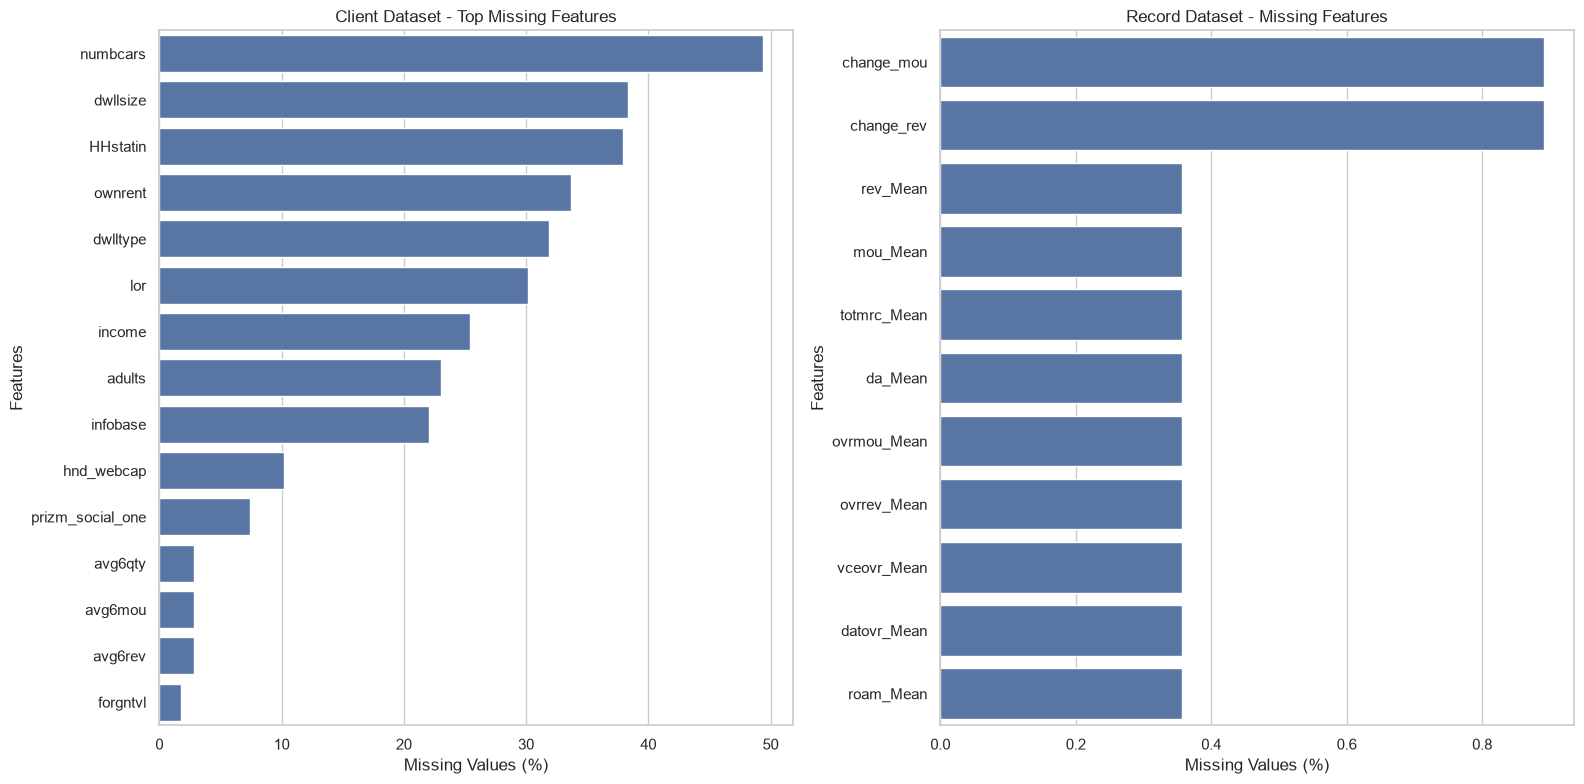

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Client dataset - top 15 missing columns
client_missing_pct = (client_df.isnull().mean() * 100)
client_missing_pct = client_missing_pct[client_missing_pct > 0]
client_missing_pct = client_missing_pct.sort_values(ascending=False).head(15)

sns.barplot(
    x=client_missing_pct.values,
    y=client_missing_pct.index,
    ax=axes[0]
)

axes[0].set_title("Client Dataset - Top Missing Features")
axes[0].set_xlabel("Missing Values (%)")
axes[0].set_ylabel("Features")

# Record dataset - all columns with missing values
record_missing_pct = (record_df.isnull().mean() * 100)
record_missing_pct = record_missing_pct[record_missing_pct > 0]
record_missing_pct = record_missing_pct.sort_values(ascending=False)

sns.barplot(
    x=record_missing_pct.values,
    y=record_missing_pct.index,
    ax=axes[1]
)

axes[1].set_title("Record Dataset - Missing Features")
axes[1].set_xlabel("Missing Values (%)")
axes[1].set_ylabel("Features")

plt.tight_layout()
plt.show()

## 4. Customer ID Validation and Target Variable Analysis

Before integrating the customer profile and behavioral datasets, we validate the customer identifiers to ensure that the datasets can be combined correctly.

We also investigate the target variable, churn, to understand the proportion of customers who have churned and those who have remained active.

In [12]:
# Compare customer IDs between datasets
client_ids = set(client_df['Customer_ID'])
record_ids = set(record_df['Customer_ID'])

print("CLIENT ID ANALYSIS")
print("-" * 40)

print("Unique IDs in Client:", len(client_ids))
print("Unique IDs in Record:", len(record_ids))

print("IDs present in both datasets:", len(client_ids & record_ids))
print("IDs only in Client:", len(client_ids - record_ids))
print("IDs only in Record:", len(record_ids - client_ids))

# Check whether the datasets contain exactly the same customers
print("\nDo both datasets contain the same customers?")
print(client_ids == record_ids)

# Check churn variable
print("\nRECORD DATASET TARGET VARIABLES")
print("-" * 40)

if 'churn' in record_df.columns:
    print("Churn column found!")
    print("\nChurn value counts:")
    print(record_df['churn'].value_counts(dropna=False))

    print("\nChurn percentages:")
    print((record_df['churn'].value_counts(normalize=True, dropna=False) * 100).round(2))
else:
    print("Churn column not found.")
    print("Available columns:")
    print(record_df.columns.tolist())

CLIENT ID ANALYSIS
----------------------------------------
Unique IDs in Client: 100000
Unique IDs in Record: 100000
IDs present in both datasets: 100000
IDs only in Client: 0
IDs only in Record: 0

Do both datasets contain the same customers?
True

RECORD DATASET TARGET VARIABLES
----------------------------------------
Churn column found!

Churn value counts:
churn
0    50438
1    49562
Name: count, dtype: int64

Churn percentages:
churn
0   50.44
1   49.56
Name: proportion, dtype: float64


In [13]:
client_ids = set(client_df['Customer_ID'])
record_ids = set(record_df['Customer_ID'])

print("CUSTOMER ID VALIDATION")
print("-" * 45)

print(f"Unique IDs in Client: {len(client_ids):,}")
print(f"Unique IDs in Record: {len(record_ids):,}")
print(f"IDs present in both: {len(client_ids & record_ids):,}")
print(f"IDs only in Client: {len(client_ids - record_ids):,}")
print(f"IDs only in Record: {len(record_ids - client_ids):,}")

print("\nDo both datasets contain exactly the same customers?")
print(client_ids == record_ids)

CUSTOMER ID VALIDATION
---------------------------------------------
Unique IDs in Client: 100,000
Unique IDs in Record: 100,000
IDs present in both: 100,000
IDs only in Client: 0
IDs only in Record: 0

Do both datasets contain exactly the same customers?
True


In [15]:
print("CHURN VALUE COUNTS")
print("-" * 45)

print(record_df['churn'].value_counts())

print("\nCHURN PERCENTAGES")
print("-" * 45)

churn_percentage = (
    record_df['churn']
    .value_counts(normalize=True) * 100
)

print(churn_percentage.round(2))

CHURN VALUE COUNTS
---------------------------------------------
churn
0    50438
1    49562
Name: count, dtype: int64

CHURN PERCENTAGES
---------------------------------------------
churn
0   50.44
1   49.56
Name: proportion, dtype: float64


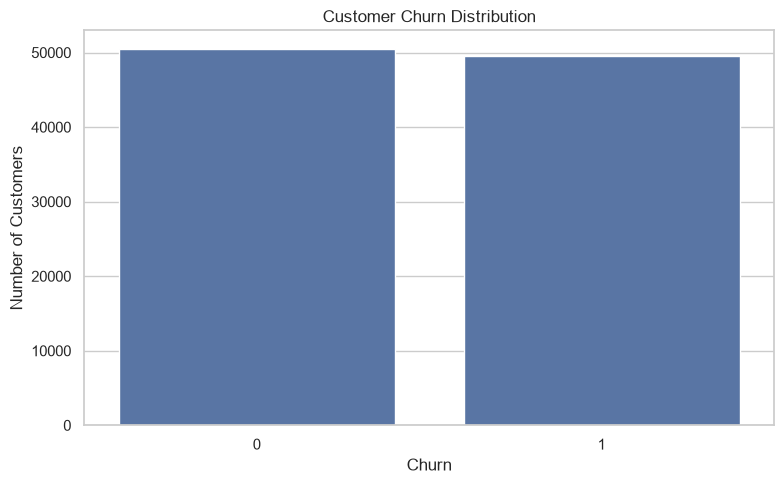

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(data=record_df, x='churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

## 5. Data Integration

The customer profile dataset and behavioral dataset are integrated using the common `Customer_ID` identifier.

A one-to-one merge is used to ensure that each customer profile corresponds to exactly one behavioral record. We also verify the resulting dataset dimensions and integrity after merging.

In [18]:
# Merge both datasets using Customer_ID
df = pd.merge(
    client_df,
    record_df,
    on='Customer_ID',
    how='inner',
    validate='one_to_one'
)

# Dataset validation
print("DATA INTEGRATION RESULTS")
print("=" * 50)

print(f"Client dataset shape: {client_df.shape}")
print(f"Record dataset shape: {record_df.shape}")
print(f"Merged dataset shape: {df.shape}")

print(f"\nUnique customers in merged dataset: {df['Customer_ID'].nunique():,}")
print(f"Duplicate rows after merging: {df.duplicated().sum()}")
print(f"Duplicate Customer_IDs after merging: {df['Customer_ID'].duplicated().sum()}")

print("\nMerge completed successfully!")

DATA INTEGRATION RESULTS
Client dataset shape: (100000, 50)
Record dataset shape: (100000, 51)
Merged dataset shape: (100000, 100)

Unique customers in merged dataset: 100,000
Duplicate rows after merging: 0
Duplicate Customer_IDs after merging: 0

Merge completed successfully!


## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the structure, distribution, variability, and relationships within the merged dataset. This process helps identify relevant customer characteristics, behavioral patterns, and potential factors associated with churn.


In [19]:
print("MERGED DATASET OVERVIEW")
print("=" * 60)

print(f"Total rows: {df.shape[0]:,}")
print(f"Total columns: {df.shape[1]:,}")
print(f"Unique customers: {df['Customer_ID'].nunique():,}")

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

MERGED DATASET OVERVIEW
Total rows: 100,000
Total columns: 100
Unique customers: 100,000

First 5 rows:


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months
0,2,1,U,A,N,1652,4228.00,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.00,136.00,38.00,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.99,2.00,2.00,WCMB,0.00,0.00,O,15.00,S,S,1.00,M,4.00,3.00,C,A,0.00,N,U,U,U,U,U,Y,361.00,1000001,24.00,219.25,22.50,0.25,0.00,0.00,0.00,0.00,0.00,-157.25,-19.00,0.67,0.00,0.67,0.00,6.33,0.00,52.33,0.00,42.33,0.00,45.00,0.00,0.00,0.00,0.00,18.00,0.00,90.64,0.00,97.18,0.00,0.00,0.00,0.00,58.00,0.00,132.60,0.00,24.00,0.00,55.22,0.00,1.33,52.33,45.00,0.00,0.33,1,61
1,1,1,N,EA,N,14654,26400.00,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.00,275.00,48.00,U,CHICAGO AREA,N,N,NaN,7.00,6.00,WC,1.00,1.00,NaN,1.00,S,S,1.00,M,5.00,1.00,C,A,0.00,Z,U,U,U,U,U,Y,240.00,1000002,57.49,482.75,37.42,0.25,22.75,9.10,9.10,0.00,0.00,532.25,50.99,8.33,0.00,1.00,0.00,61.33,0.00,263.33,0.00,69.00,0.00,193.33,0.00,1.67,6.33,5.46,53.00,0.33,189.40,0.00,55.28,46.33,24.22,6.33,3.70,83.67,0.00,75.33,0.00,157.00,0.00,169.34,0.00,9.33,263.33,193.33,0.00,5.67,0,56
2,1,1,Y,C,N,7903,24385.05,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.00,6.00,17.00,S,GREAT LAKES AREA,N,N,29.99,2.00,1.00,NaN,0.00,0.00,O,7.00,S,M,2.00,M,5.00,2.00,C,A,0.00,N,U,Y,U,U,U,Y,1504.00,1000003,16.99,10.25,16.99,0.00,0.00,0.00,0.00,0.00,0.00,-4.25,0.00,0.33,0.00,0.00,0.00,2.67,0.00,9.00,0.00,0.33,0.00,6.00,0.00,0.00,0.00,0.00,0.33,0.00,5.43,0.00,0.00,0.00,0.00,0.00,0.00,5.00,0.00,5.19,0.00,1.00,0.00,0.23,0.00,0.33,9.00,6.00,0.00,0.00,1,58
3,1,1,Y,B,N,1502,3065.00,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.00,25.00,40.00,T,CHICAGO AREA,N,N,29.99,1.00,1.00,NaN,0.00,0.00,NaN,6.00,M,M,4.00,M,6.00,1.00,C,D,0.00,U,Y,U,U,U,U,Y,1812.00,1000004,38.00,7.50,38.00,0.00,0.00,0.00,0.00,0.00,0.00,-1.50,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.67,0.00,1.33,0.00,3.67,0.00,0.00,0.00,0.00,1.33,0.00,8.41,0.00,0.41,0.33,0.26,0.00,0.00,1.33,0.00,3.38,0.00,3.67,0.00,5.45,0.00,0.00,3.67,3.67,0.00,0.00,0,60
4,1,1,Y,A,N,4485,14028.00,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.00,196.00,80.00,U,NEW ENGLAND AREA,Y,N,149.99,6.00,4.00,WCMB,0.00,0.00,R,5.00,M,S,1.00,M,6.00,1.00,C,O,0.00,I,U,U,U,U,U,Y,434.00,1000005,55.23,570.50,71.98,0.00,0.00,0.00,0.00,0.00,0.00,38.50,0.00,9.67,0.00,0.67,0.00,77.00,0.00,222.33,0.00,94.67,0.00,137.00,0.00,8.67,15.00,11.08,66.00,0.00,285.23,0.00,106.33,14.67,10.82,0.67,0.37,97.33,0.00,173.48,0.00,90.33,0.00,218.09,0.00,10.33,222.33,137.00,0.00,0.00,0,57



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 100 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   uniqsubs          100000 non-null  int64  
 1   actvsubs          100000 non-null  int64  
 2   new_cell          100000 non-null  str    
 3   crclscod          100000 non-null  str    
 4   asl_flag          100000 non-null  str    
 5   totcalls          100000 non-null  int64  
 6   totmou            100000 non-null  float64
 7   totrev            100000 non-null  float64
 8   adjrev            100000 non-null  float64
 9   adjmou            100000 non-null  float64
 10  adjqty            100000 non-null  int64  
 11  avgrev            100000 non-null  float64
 12  avgmou            100000 non-null  float64
 13  avgqty            100000 non-null  float64
 14  avg3mou           100000 non-null  int64  
 15  avg3qty           100000 non-null  int64  
 16  avg3rev  

In [20]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
uniqsubs,100000.00,1.55,1.08,1.00,1.00,1.00,2.00,196.00
actvsubs,100000.00,1.36,0.66,0.00,1.00,1.00,2.00,53.00
totcalls,100000.00,2877.14,3790.86,0.00,889.00,1822.00,3492.00,98874.00
totmou,100000.00,7648.36,8666.56,0.00,2529.00,5191.50,9776.00,233419.10
totrev,100000.00,1031.92,852.91,3.65,518.98,804.53,1263.77,27321.50
adjrev,100000.00,960.11,840.17,2.40,452.18,737.76,1188.18,27071.30
adjmou,100000.00,7546.31,8594.89,0.00,2474.00,5102.50,9661.00,232855.10
adjqty,100000.00,2836.37,3756.51,0.00,868.00,1789.00,3442.00,98705.00
avgrev,100000.00,57.91,36.16,0.48,35.37,49.89,69.48,924.27
avgmou,100000.00,483.73,438.49,0.00,176.14,360.19,655.67,7040.13


In [21]:
numerical_features = df.select_dtypes(include=np.number).columns.tolist()
categorical_features = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print(f"Numerical features: {len(numerical_features)}")
print(f"Categorical features: {len(categorical_features)}")

print("\nNumerical columns:")
print(numerical_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 79
Categorical features: 21

Numerical columns:
['uniqsubs', 'actvsubs', 'totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty', 'avg3mou', 'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty', 'avg6rev', 'hnd_price', 'phones', 'models', 'truck', 'rv', 'lor', 'adults', 'income', 'numbcars', 'forgntvl', 'eqpdays', 'Customer_ID', 'rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'drop_dat_Mean', 'blck_vce_Mean', 'blck_dat_Mean', 'unan_vce_Mean', 'unan_dat_Mean', 'plcd_vce_Mean', 'plcd_dat_Mean', 'recv_vce_Mean', 'recv_sms_Mean', 'comp_vce_Mean', 'comp_dat_Mean', 'custcare_Mean', 'ccrndmou_Mean', 'cc_mou_Mean', 'inonemin_Mean', 'threeway_Mean', 'mou_cvce_Mean', 'mou_cdat_Mean', 'mou_rvce_Mean', 'owylis_vce_Mean', 'mouowylisv_Mean', 'iwylis_vce_Mean', 'mouiwylisv_Mean', 'peak_vce_Mean', 'peak_dat_Mean', 'mou_peav_Mean', 'mou_pea

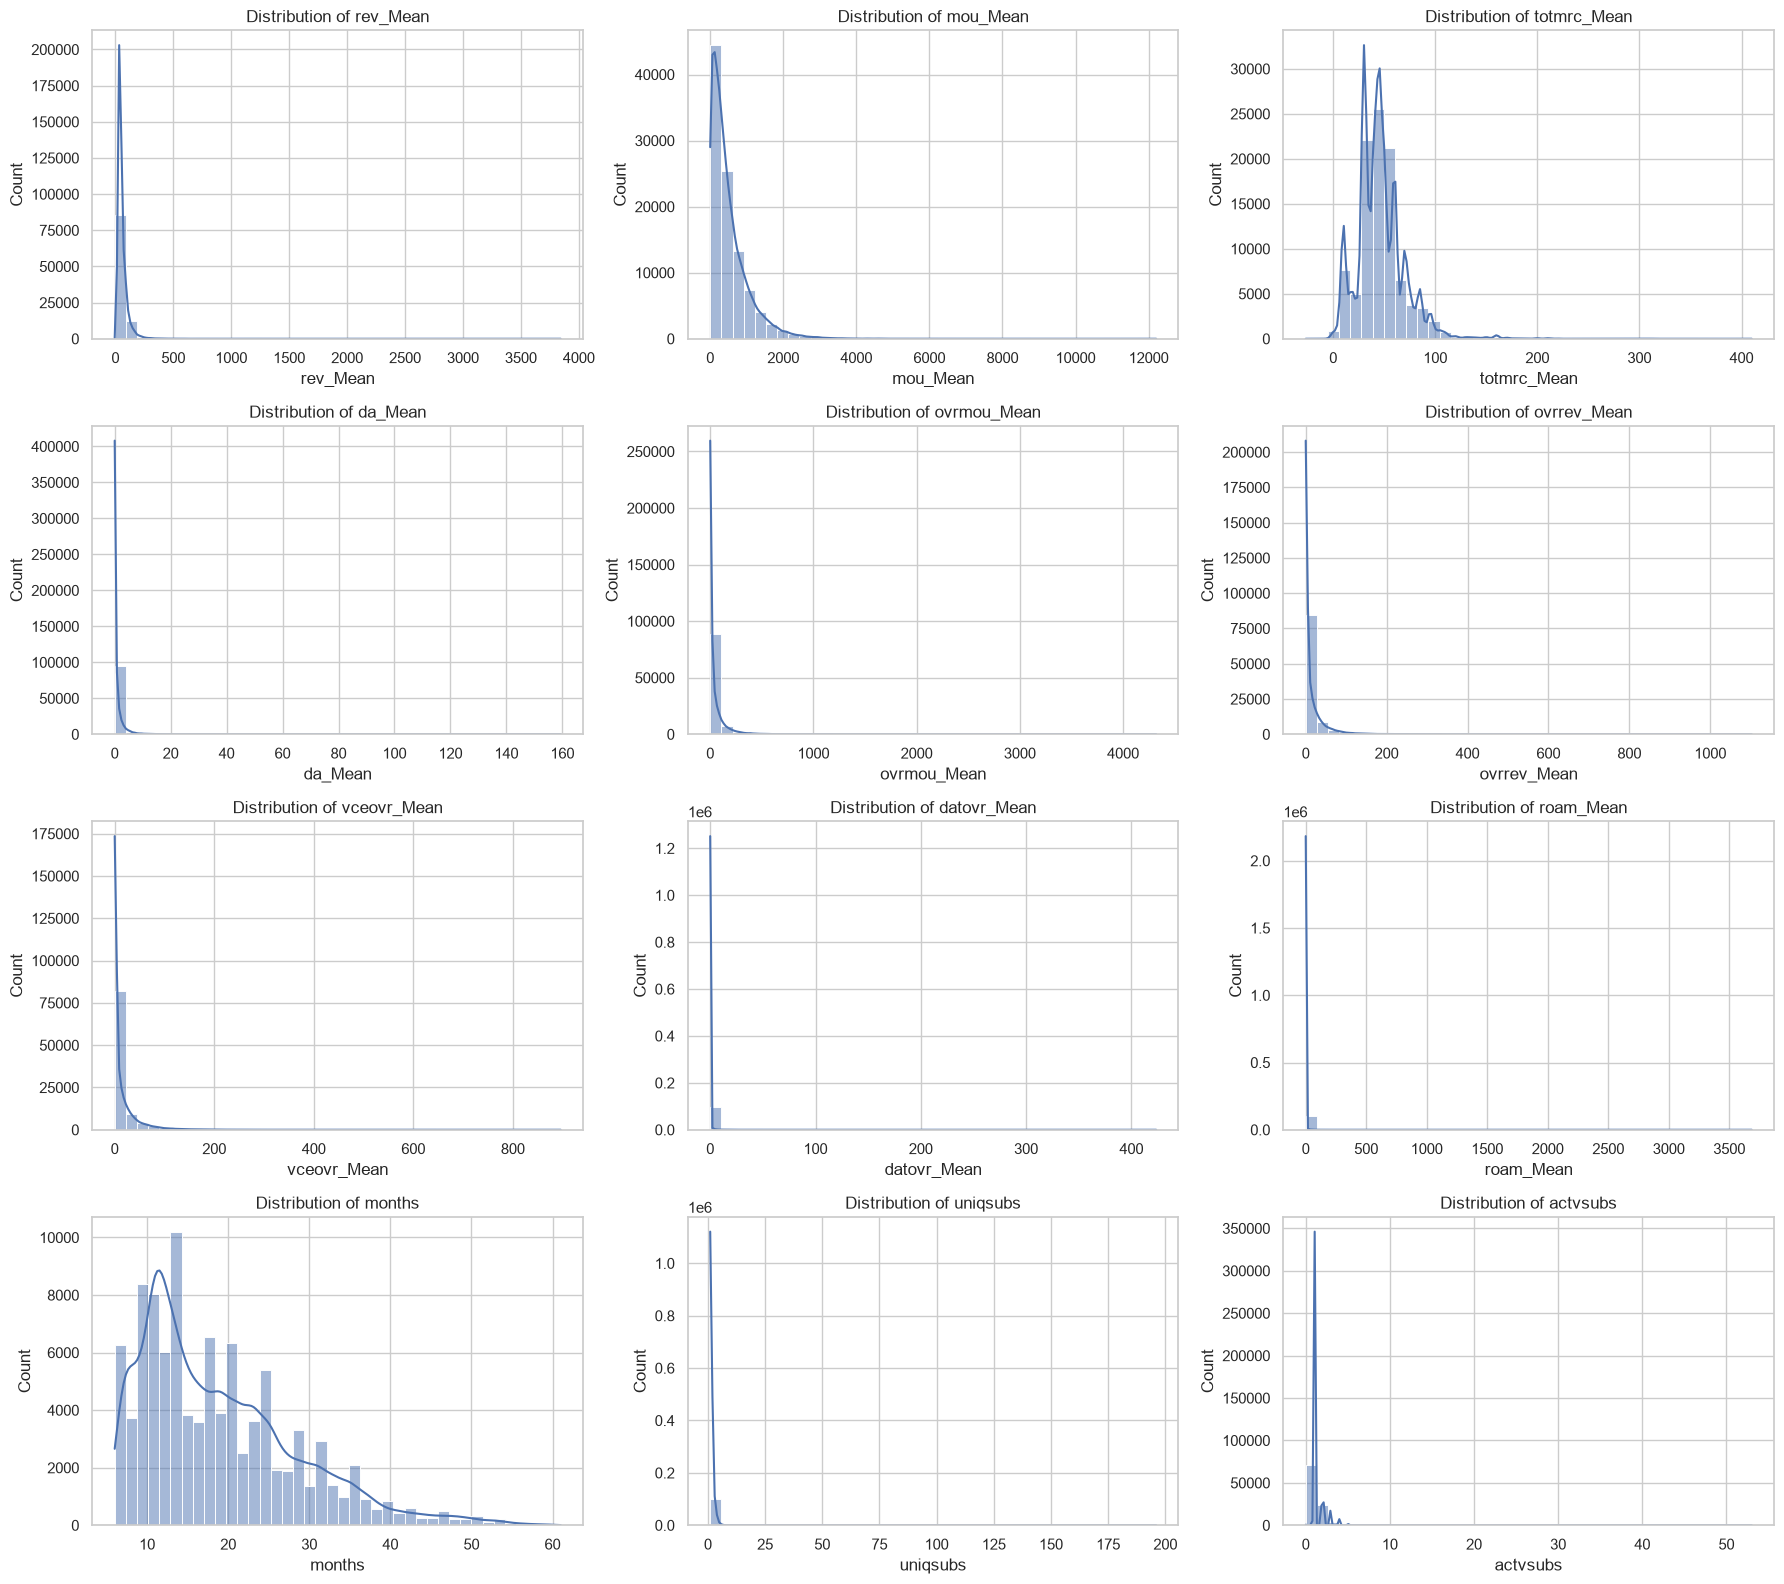

In [22]:
# Select important numerical features for analysis
important_features = [
    'rev_Mean',
    'mou_Mean',
    'totmrc_Mean',
    'da_Mean',
    'ovrmou_Mean',
    'ovrrev_Mean',
    'vceovr_Mean',
    'datovr_Mean',
    'roam_Mean',
    'months',
    'uniqsubs',
    'actvsubs'
]

# Plot distributions
fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()

for i, feature in enumerate(important_features):
    sns.histplot(df[feature], bins=40, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {feature}')
    axes[i].set_xlabel(feature)

plt.tight_layout()
plt.show()

In [23]:
# Compare numerical features between churned and retained customers

comparison_features = [
    'rev_Mean',
    'mou_Mean',
    'totmrc_Mean',
    'da_Mean',
    'ovrmou_Mean',
    'ovrrev_Mean',
    'vceovr_Mean',
    'datovr_Mean',
    'roam_Mean',
    'months',
    'uniqsubs',
    'actvsubs'
]

churn_comparison = df.groupby('churn')[comparison_features].mean().T

churn_comparison.columns = ['Retained Customers (0)', 'Churned Customers (1)']

# Calculate absolute difference
churn_comparison['Difference'] = (
    churn_comparison['Churned Customers (1)'] -
    churn_comparison['Retained Customers (0)']
)

display(churn_comparison.round(2))

,Retained Customers (0),Churned Customers (1),Difference
rev_Mean,59.22,58.21,-1.01
mou_Mean,543.21,483.31,-59.90
totmrc_Mean,47.78,44.54,-3.24
da_Mean,0.92,0.86,-0.06
ovrmou_Mean,39.17,43.01,3.84
ovrrev_Mean,12.84,14.29,1.45
vceovr_Mean,12.57,14.03,1.46
datovr_Mean,0.27,0.26,-0.01
roam_Mean,1.15,1.42,0.27
months,18.63,19.04,0.41


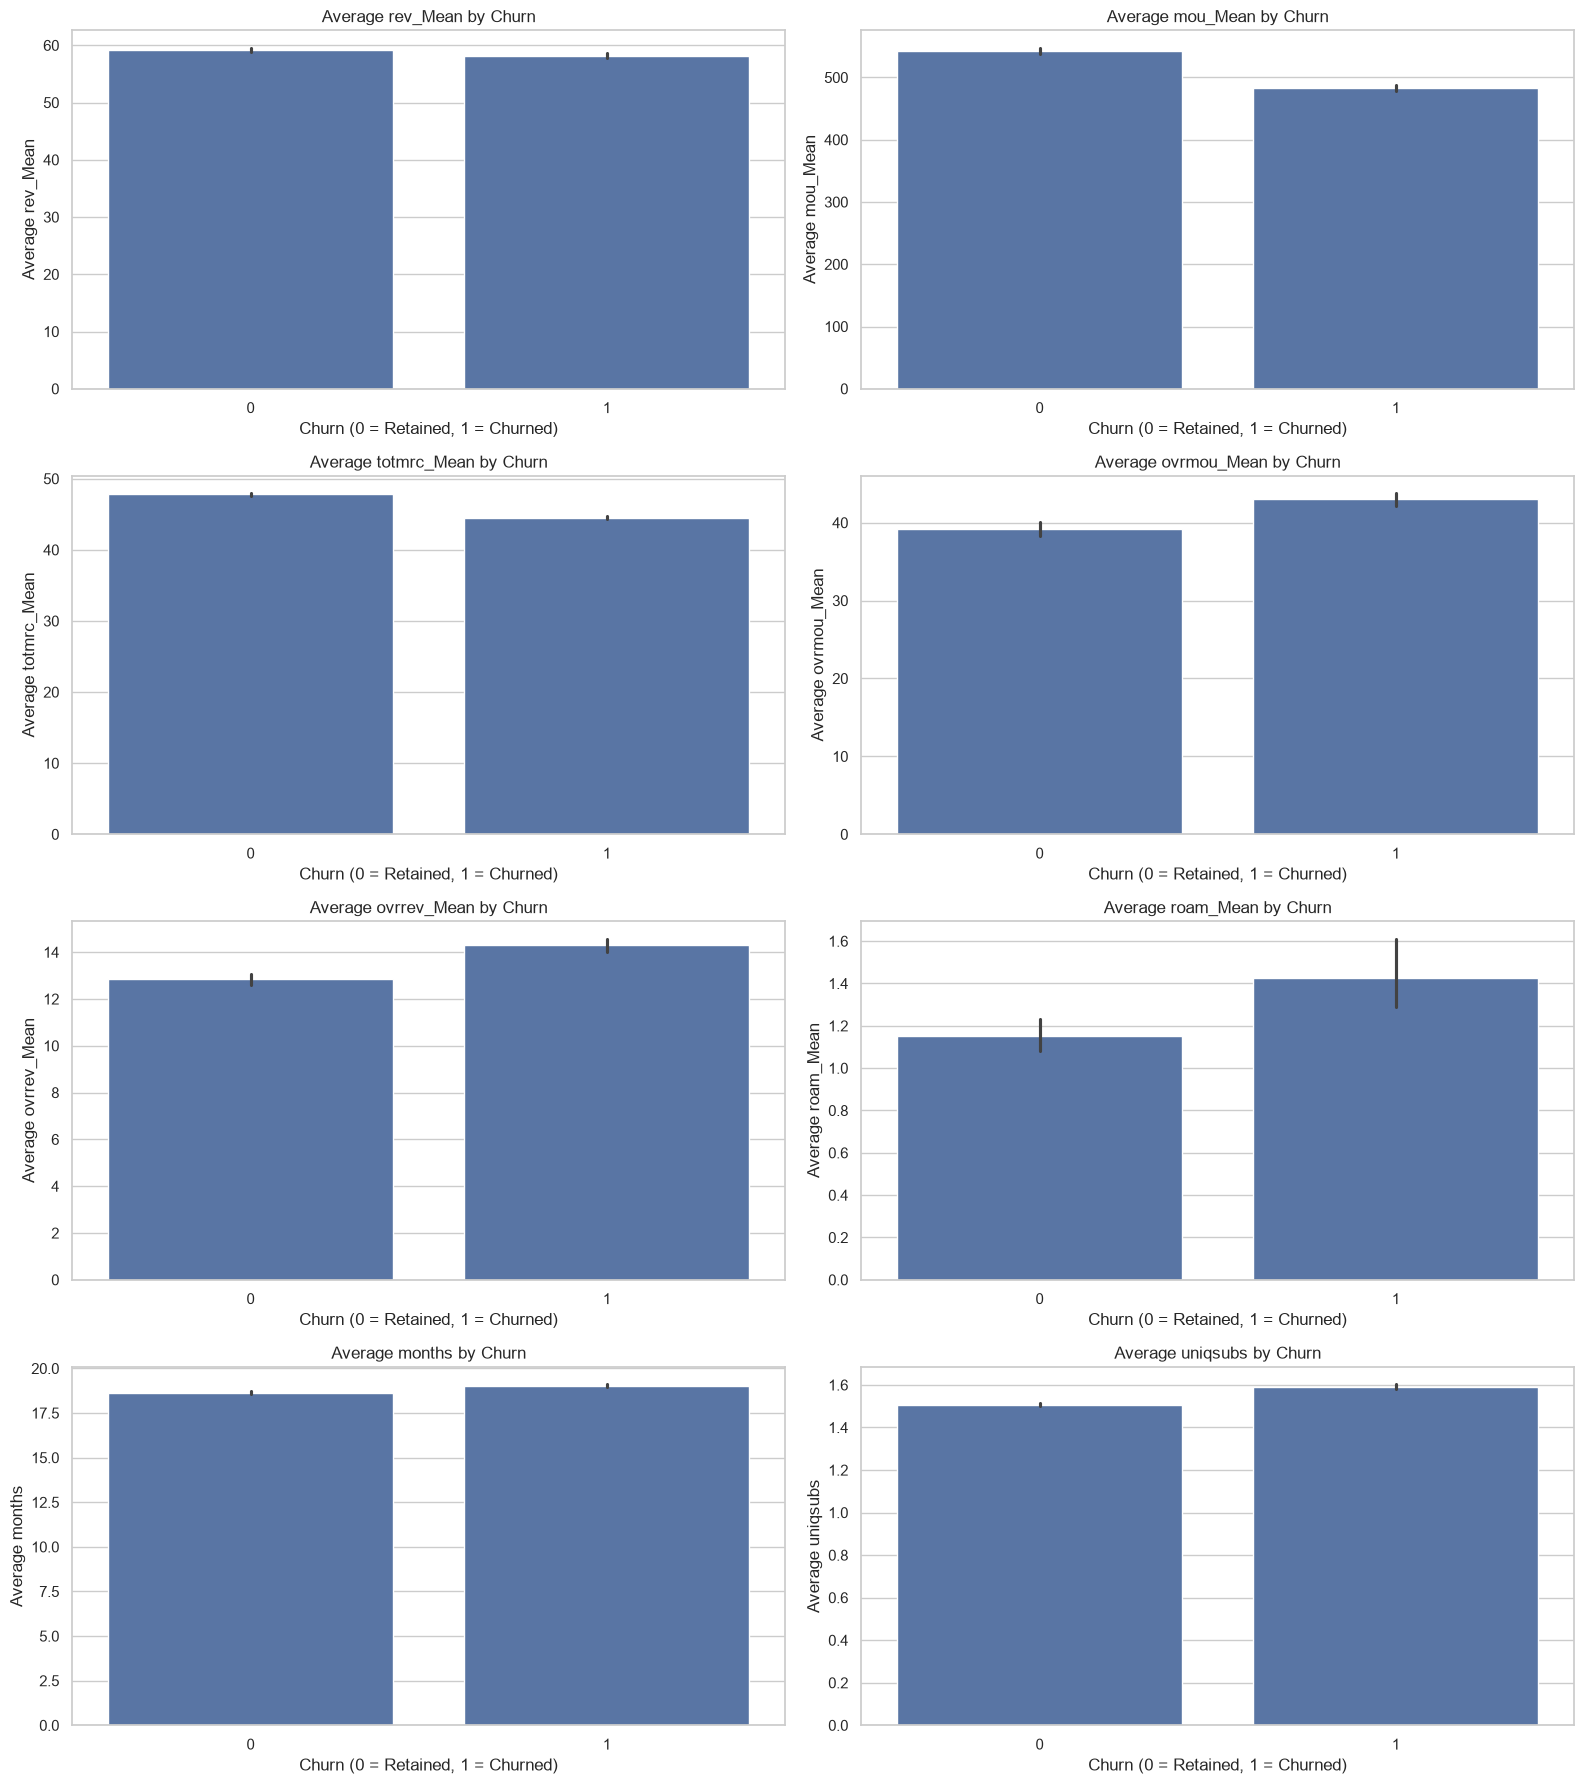

In [24]:
# Compare churned vs retained customers visually

features_to_plot = [
    'rev_Mean',
    'mou_Mean',
    'totmrc_Mean',
    'ovrmou_Mean',
    'ovrrev_Mean',
    'roam_Mean',
    'months',
    'uniqsubs'
]

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    sns.barplot(
        data=df,
        x='churn',
        y=feature,
        estimator='mean',
        ax=axes[i]
    )
    axes[i].set_title(f'Average {feature} by Churn')
    axes[i].set_xlabel('Churn (0 = Retained, 1 = Churned)')
    axes[i].set_ylabel(f'Average {feature}')

plt.tight_layout()
plt.show()

In [25]:
# Selected categorical features
categorical_to_analyze = [
    'area',
    'prizm_social_one',
    'HHstatin',
    'dwlltype',
    'dwllsize',
    'ownrent',
    'marital',
    'ethnic',
    'infobase',
    'creditcd',
    'hnd_webcap',
    'hnd_price'
]

# Keep only columns that exist in our dataset
categorical_to_analyze = [
    col for col in categorical_to_analyze if col in df.columns
]

print("Categorical features selected:", categorical_to_analyze)

Categorical features selected: ['area', 'prizm_social_one', 'HHstatin', 'dwlltype', 'dwllsize', 'ownrent', 'marital', 'ethnic', 'infobase', 'creditcd', 'hnd_webcap', 'hnd_price']


In [26]:
# Analyze churn across categorical segments

categorical_results = []

for feature in categorical_to_analyze:
    temp = df.groupby(feature, dropna=False)['churn'].agg(
        customers='count',
        churned='sum',
        churn_rate='mean'
    ).reset_index()

    temp['feature'] = feature
    temp['churn_rate'] = temp['churn_rate'] * 100

    categorical_results.append(temp)

categorical_analysis = pd.concat(categorical_results, ignore_index=True)

display(
    categorical_analysis.sort_values(
        ['feature', 'churn_rate'],
        ascending=[True, False]
    ).round(2)
)

,area,customers,churned,churn_rate,feature,prizm_social_one,HHstatin,dwlltype,dwllsize,ownrent,marital,ethnic,infobase,creditcd,hnd_webcap,hnd_price
30,NaN,923,482,52.22,HHstatin,NaN,H,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
32,NaN,37923,19336,50.99,HHstatin,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29,NaN,1766,888,50.28,HHstatin,NaN,G,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26,NaN,4666,2329,49.91,HHstatin,NaN,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28,NaN,39124,19029,48.64,HHstatin,NaN,C,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25,NaN,7388,3810,51.57,prizm_social_one,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23,NaN,14989,7620,50.84,prizm_social_one,T,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20,NaN,17018,8352,49.08,prizm_social_one,C,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
22,NaN,32097,15752,49.08,prizm_social_one,S,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


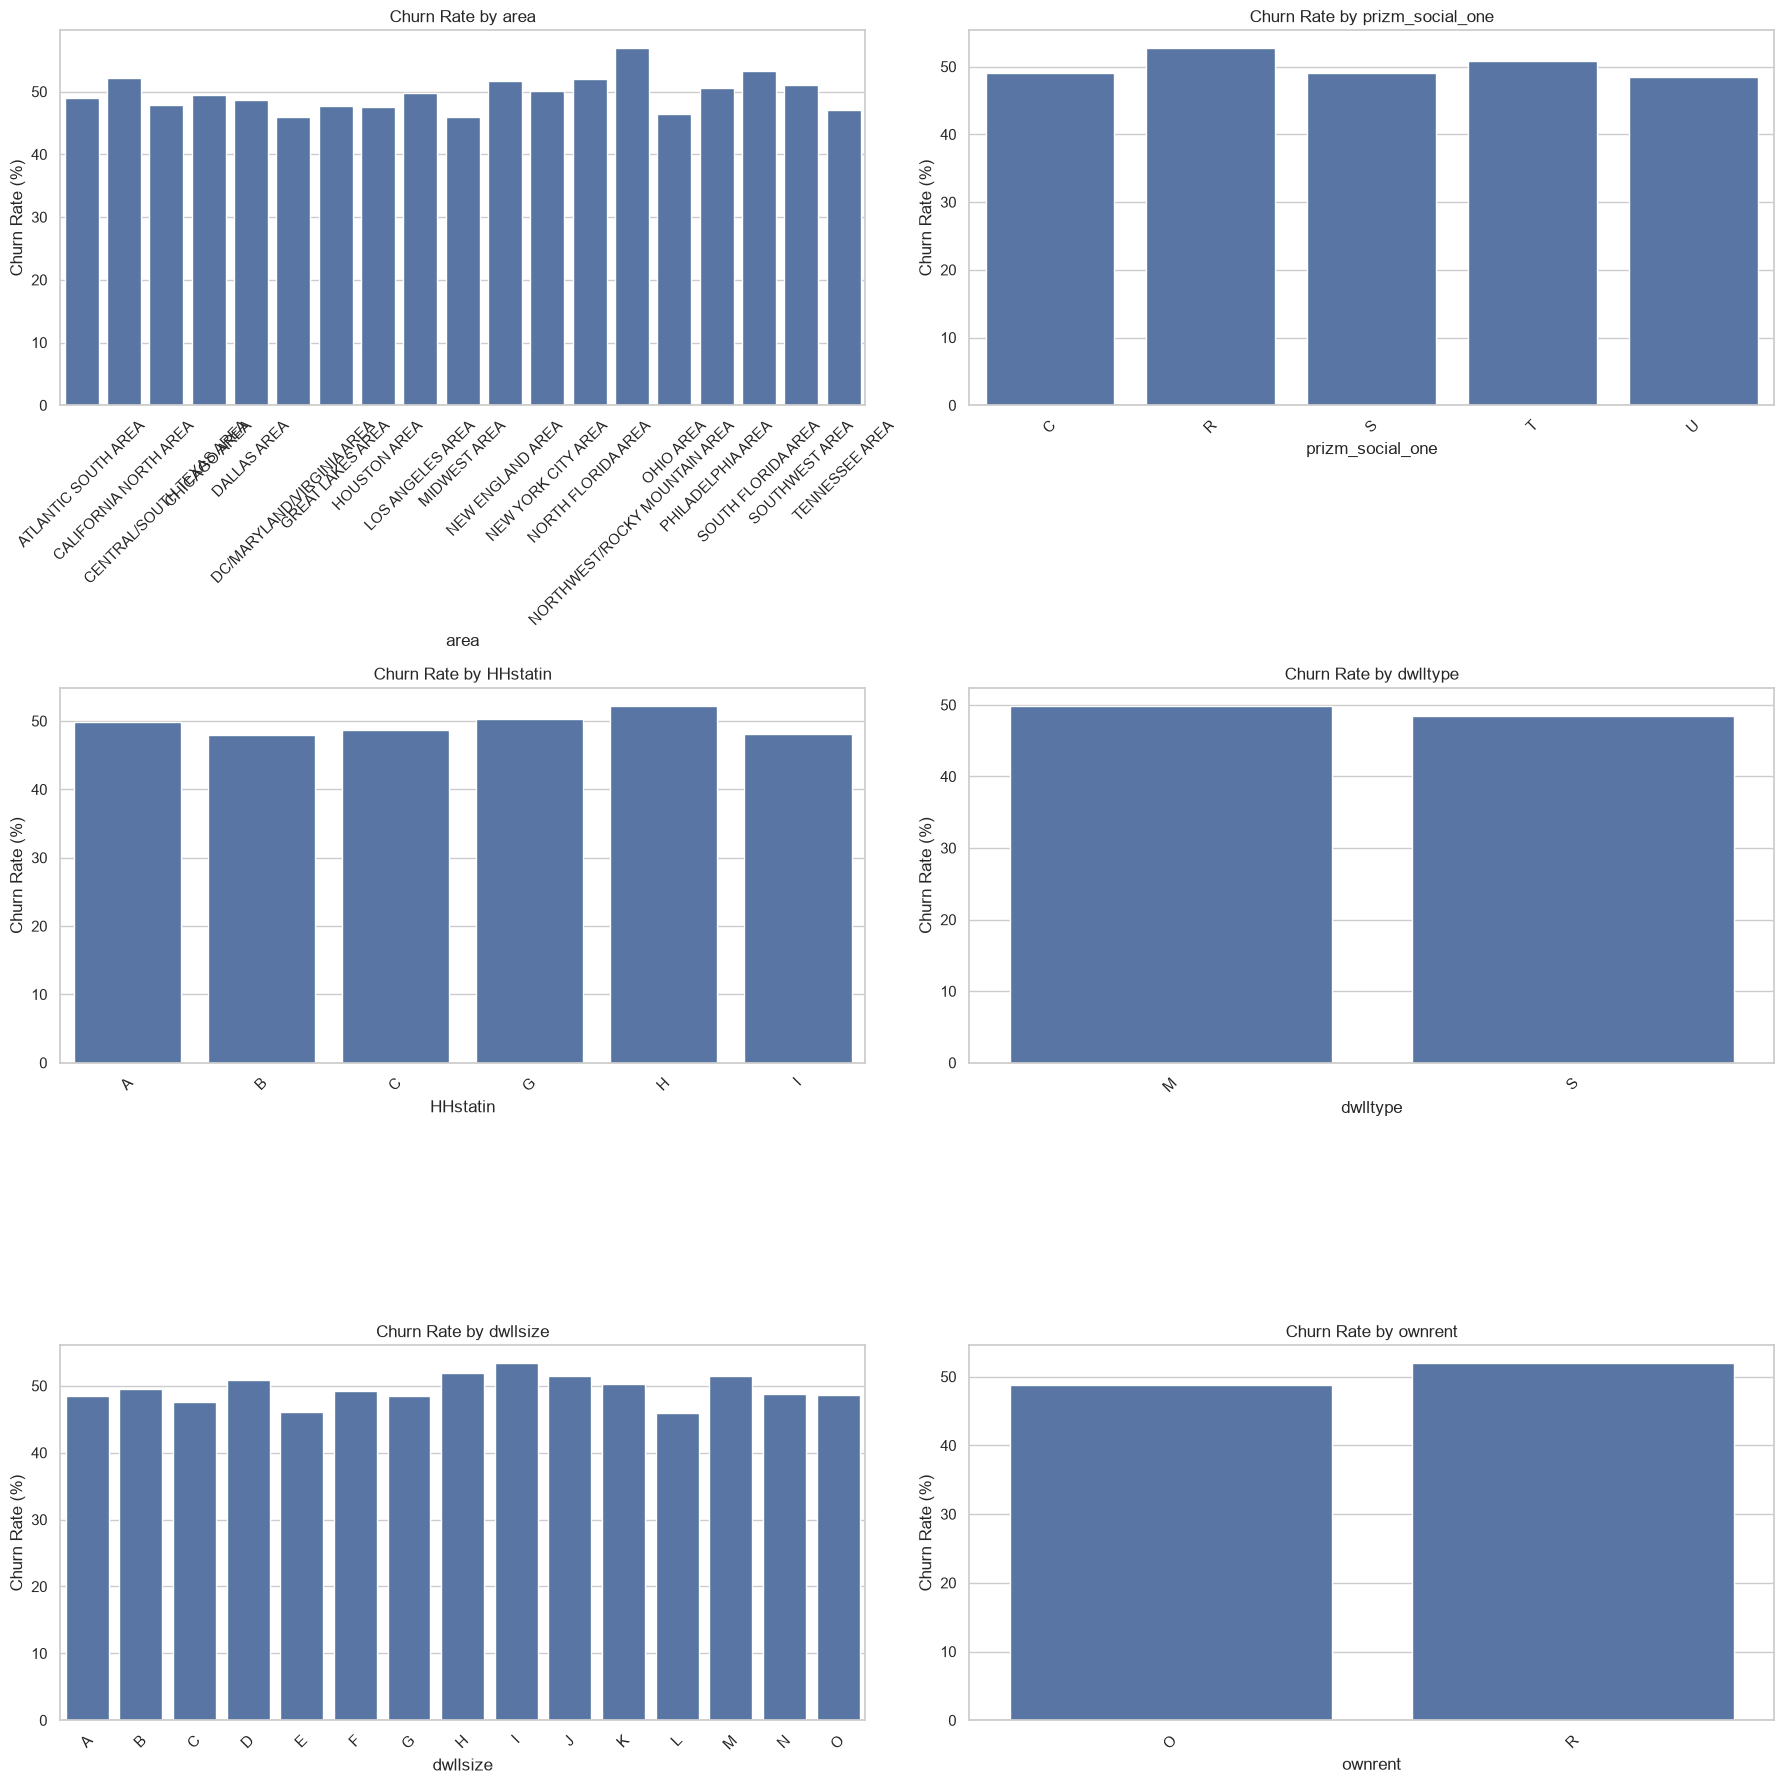

In [27]:
# Plot churn rates across selected categorical variables

features_to_plot = categorical_to_analyze[:6]

fig, axes = plt.subplots(3, 2, figsize=(18, 18))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    plot_data = (
        df.groupby(feature, dropna=False)['churn']
        .mean()
        .reset_index()
    )

    plot_data['churn'] = plot_data['churn'] * 100

    sns.barplot(
        data=plot_data,
        x=feature,
        y='churn',
        ax=axes[i]
    )

    axes[i].set_title(f'Churn Rate by {feature}')
    axes[i].set_ylabel('Churn Rate (%)')
    axes[i].set_xlabel(feature)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

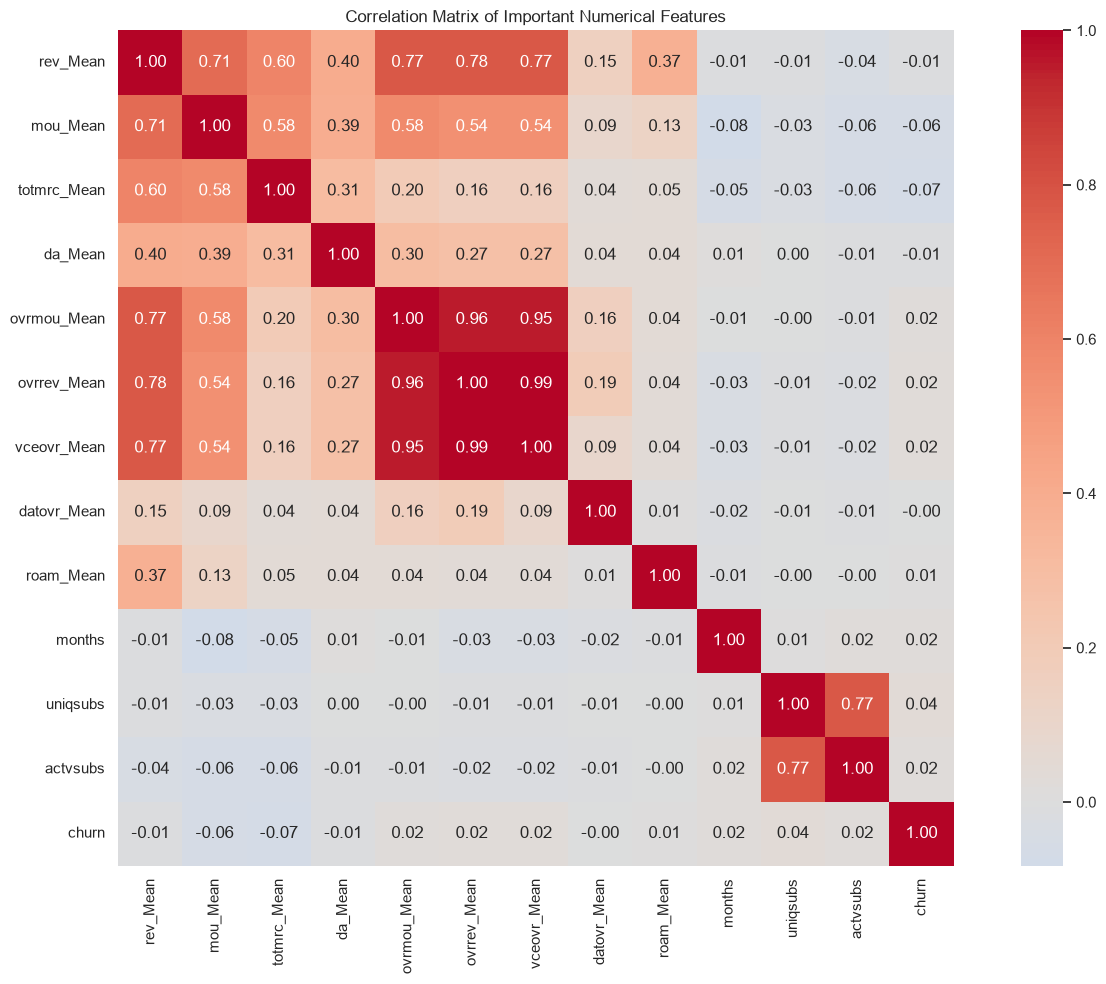

In [28]:
# Correlation analysis of numerical variables

correlation_features = [
    'rev_Mean',
    'mou_Mean',
    'totmrc_Mean',
    'da_Mean',
    'ovrmou_Mean',
    'ovrrev_Mean',
    'vceovr_Mean',
    'datovr_Mean',
    'roam_Mean',
    'months',
    'uniqsubs',
    'actvsubs',
    'churn'
]

correlation_matrix = df[correlation_features].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True
)

plt.title('Correlation Matrix of Important Numerical Features')
plt.tight_layout()
plt.show()

In [29]:
# Identify features most correlated with churn

churn_correlations = correlation_matrix['churn'].drop('churn')

churn_correlations = churn_correlations.sort_values(
    key=lambda x: x.abs(),
    ascending=False
)

print("Correlation with Churn:")
display(churn_correlations.to_frame(name='Correlation with Churn').round(4))

Correlation with Churn:


,Correlation with Churn
totmrc_Mean,-0.07
mou_Mean,-0.06
uniqsubs,0.04
vceovr_Mean,0.02
ovrrev_Mean,0.02
months,0.02
ovrmou_Mean,0.02
actvsubs,0.02
da_Mean,-0.01
rev_Mean,-0.01


In [30]:
# Review missing values across the merged dataset

missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': df.isnull().mean() * 100
})

missing_summary = missing_summary[
    missing_summary['Missing Count'] > 0
].sort_values('Missing Percentage', ascending=False)

print("FEATURES WITH MISSING VALUES")
display(missing_summary.round(2))

print("\n" + "=" * 60)
print("FEATURE TYPE SUMMARY")
print("=" * 60)

print("Numerical features:", df.select_dtypes(include=np.number).shape[1])
print("Categorical features:", df.select_dtypes(include=['object', 'category']).shape[1])

print("\nTarget variable distribution:")
display(df['churn'].value_counts())

print("\nTarget variable percentages:")
display((df['churn'].value_counts(normalize=True) * 100).round(2))

FEATURES WITH MISSING VALUES


,Missing Count,Missing Percentage
numbcars,49366,49.37
dwllsize,38308,38.31
HHstatin,37923,37.92
ownrent,33706,33.71
dwlltype,31909,31.91
lor,30190,30.19
income,25436,25.44
adults,23019,23.02
infobase,22079,22.08
hnd_webcap,10189,10.19



FEATURE TYPE SUMMARY
Numerical features: 79
Categorical features: 21

Target variable distribution:


churn
0    50438
1    49562
Name: count, dtype: int64


Target variable percentages:


churn
0   50.44
1   49.56
Name: proportion, dtype: float64

In [31]:
# Separate features (X) and target (y)

X = df.drop(columns=['Customer_ID', 'churn'])
y = df['churn']

print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nFeature preview:")
display(X.head())

Feature matrix shape: (100000, 98)
Target variable shape: (100000,)

Target distribution:
churn
0    50438
1    49562
Name: count, dtype: int64

Feature preview:


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,months
0,2,1,U,A,N,1652,4228.00,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.00,136.00,38.00,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.99,2.00,2.00,WCMB,0.00,0.00,O,15.00,S,S,1.00,M,4.00,3.00,C,A,0.00,N,U,U,U,U,U,Y,361.00,24.00,219.25,22.50,0.25,0.00,0.00,0.00,0.00,0.00,-157.25,-19.00,0.67,0.00,0.67,0.00,6.33,0.00,52.33,0.00,42.33,0.00,45.00,0.00,0.00,0.00,0.00,18.00,0.00,90.64,0.00,97.18,0.00,0.00,0.00,0.00,58.00,0.00,132.60,0.00,24.00,0.00,55.22,0.00,1.33,52.33,45.00,0.00,0.33,61
1,1,1,N,EA,N,14654,26400.00,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.00,275.00,48.00,U,CHICAGO AREA,N,N,NaN,7.00,6.00,WC,1.00,1.00,NaN,1.00,S,S,1.00,M,5.00,1.00,C,A,0.00,Z,U,U,U,U,U,Y,240.00,57.49,482.75,37.42,0.25,22.75,9.10,9.10,0.00,0.00,532.25,50.99,8.33,0.00,1.00,0.00,61.33,0.00,263.33,0.00,69.00,0.00,193.33,0.00,1.67,6.33,5.46,53.00,0.33,189.40,0.00,55.28,46.33,24.22,6.33,3.70,83.67,0.00,75.33,0.00,157.00,0.00,169.34,0.00,9.33,263.33,193.33,0.00,5.67,56
2,1,1,Y,C,N,7903,24385.05,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.00,6.00,17.00,S,GREAT LAKES AREA,N,N,29.99,2.00,1.00,NaN,0.00,0.00,O,7.00,S,M,2.00,M,5.00,2.00,C,A,0.00,N,U,Y,U,U,U,Y,1504.00,16.99,10.25,16.99,0.00,0.00,0.00,0.00,0.00,0.00,-4.25,0.00,0.33,0.00,0.00,0.00,2.67,0.00,9.00,0.00,0.33,0.00,6.00,0.00,0.00,0.00,0.00,0.33,0.00,5.43,0.00,0.00,0.00,0.00,0.00,0.00,5.00,0.00,5.19,0.00,1.00,0.00,0.23,0.00,0.33,9.00,6.00,0.00,0.00,58
3,1,1,Y,B,N,1502,3065.00,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.00,25.00,40.00,T,CHICAGO AREA,N,N,29.99,1.00,1.00,NaN,0.00,0.00,NaN,6.00,M,M,4.00,M,6.00,1.00,C,D,0.00,U,Y,U,U,U,U,Y,1812.00,38.00,7.50,38.00,0.00,0.00,0.00,0.00,0.00,0.00,-1.50,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.67,0.00,1.33,0.00,3.67,0.00,0.00,0.00,0.00,1.33,0.00,8.41,0.00,0.41,0.33,0.26,0.00,0.00,1.33,0.00,3.38,0.00,3.67,0.00,5.45,0.00,0.00,3.67,3.67,0.00,0.00,60
4,1,1,Y,A,N,4485,14028.00,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.00,196.00,80.00,U,NEW ENGLAND AREA,Y,N,149.99,6.00,4.00,WCMB,0.00,0.00,R,5.00,M,S,1.00,M,6.00,1.00,C,O,0.00,I,U,U,U,U,U,Y,434.00,55.23,570.50,71.98,0.00,0.00,0.00,0.00,0.00,0.00,38.50,0.00,9.67,0.00,0.67,0.00,77.00,0.00,222.33,0.00,94.67,0.00,137.00,0.00,8.67,15.00,11.08,66.00,0.00,285.23,0.00,106.33,14.67,10.82,0.67,0.37,97.33,0.00,173.48,0.00,90.33,0.00,218.09,0.00,10.33,222.33,137.00,0.00,0.00,57


In [32]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAIN-TEST SPLIT")
print("=" * 40)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nChurn distribution:")
print("Training set:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting set:")
print((y_test.value_counts(normalize=True) * 100).round(2))

TRAIN-TEST SPLIT
Training features: (80000, 98)
Testing features: (20000, 98)
Training target: (80000,)
Testing target: (20000,)

Churn distribution:
Training set:
churn
0   50.44
1   49.56
Name: proportion, dtype: float64

Testing set:
churn
0   50.44
1   49.56
Name: proportion, dtype: float64


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (80000, 98)
Testing set: (20000, 98)

Training target distribution:
churn
0   0.50
1   0.50
Name: proportion, dtype: float64

Testing target distribution:
churn
0   0.50
1   0.50
Name: proportion, dtype: float64


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("Preprocessing tools imported successfully!")

Preprocessing tools imported successfully!


In [35]:
# Identify column types from training data only

numeric_features = X_train.select_dtypes(include=['number']).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 77
Categorical features: 21

Numerical columns:
['uniqsubs', 'actvsubs', 'totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty', 'avg3mou', 'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty', 'avg6rev', 'hnd_price', 'phones', 'models', 'truck', 'rv', 'lor', 'adults', 'income', 'numbcars', 'forgntvl', 'eqpdays', 'rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'drop_dat_Mean', 'blck_vce_Mean', 'blck_dat_Mean', 'unan_vce_Mean', 'unan_dat_Mean', 'plcd_vce_Mean', 'plcd_dat_Mean', 'recv_vce_Mean', 'recv_sms_Mean', 'comp_vce_Mean', 'comp_dat_Mean', 'custcare_Mean', 'ccrndmou_Mean', 'cc_mou_Mean', 'inonemin_Mean', 'threeway_Mean', 'mou_cvce_Mean', 'mou_cdat_Mean', 'mou_rvce_Mean', 'owylis_vce_Mean', 'mouowylisv_Mean', 'iwylis_vce_Mean', 'mouiwylisv_Mean', 'peak_vce_Mean', 'peak_dat_Mean', 'mou_peav_Mean', 'mou_pead_Mean', 'opk_v

In [36]:
# Numerical preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

print("Numerical preprocessing pipeline created.")
print("Categorical preprocessing pipeline created.")

Numerical preprocessing pipeline created.
Categorical preprocessing pipeline created.


In [37]:
# Combine both pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

print("Combined preprocessing transformer created successfully!")

Combined preprocessing transformer created successfully!


In [38]:
# Fit preprocessing on training data and transform both sets

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("PREPROCESSING COMPLETE")
print("=" * 45)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nTraining data type:", type(X_train_processed))
print("Testing data type:", type(X_test_processed))

PREPROCESSING COMPLETE
Original training shape: (80000, 98)
Processed training shape: (80000, 229)

Original testing shape: (20000, 98)
Processed testing shape: (20000, 229)

Training data type: <class 'numpy.ndarray'>
Testing data type: <class 'numpy.ndarray'>


In [39]:
# Get names of transformed features

processed_feature_names = preprocessor.get_feature_names_out()

print("Total features after preprocessing:", len(processed_feature_names))
print("\nFirst 50 processed features:")
print(processed_feature_names[:50])

Total features after preprocessing: 229

First 50 processed features:
['num__uniqsubs' 'num__actvsubs' 'num__totcalls' 'num__totmou'
 'num__totrev' 'num__adjrev' 'num__adjmou' 'num__adjqty' 'num__avgrev'
 'num__avgmou' 'num__avgqty' 'num__avg3mou' 'num__avg3qty' 'num__avg3rev'
 'num__avg6mou' 'num__avg6qty' 'num__avg6rev' 'num__hnd_price'
 'num__phones' 'num__models' 'num__truck' 'num__rv' 'num__lor'
 'num__adults' 'num__income' 'num__numbcars' 'num__forgntvl'
 'num__eqpdays' 'num__rev_Mean' 'num__mou_Mean' 'num__totmrc_Mean'
 'num__da_Mean' 'num__ovrmou_Mean' 'num__ovrrev_Mean' 'num__vceovr_Mean'
 'num__datovr_Mean' 'num__roam_Mean' 'num__change_mou' 'num__change_rev'
 'num__drop_vce_Mean' 'num__drop_dat_Mean' 'num__blck_vce_Mean'
 'num__blck_dat_Mean' 'num__unan_vce_Mean' 'num__unan_dat_Mean'
 'num__plcd_vce_Mean' 'num__plcd_dat_Mean' 'num__recv_vce_Mean'
 'num__recv_sms_Mean' 'num__comp_vce_Mean']


In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Model evaluation tools imported successfully!")

Model evaluation tools imported successfully!


In [41]:
# Train Logistic Regression baseline

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [42]:
# Generate predictions

y_pred_lr = logistic_model.predict(X_test_processed)
y_prob_lr = logistic_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
lr_results = {
    'Accuracy': accuracy_score(y_test, y_pred_lr),
    'Precision': precision_score(y_test, y_pred_lr),
    'Recall': recall_score(y_test, y_pred_lr),
    'F1 Score': f1_score(y_test, y_pred_lr),
    'ROC-AUC': roc_auc_score(y_test, y_prob_lr)
}

print("LOGISTIC REGRESSION - BASELINE RESULTS")
print("=" * 45)

for metric, value in lr_results.items():
    print(f"{metric:<15}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

LOGISTIC REGRESSION - BASELINE RESULTS
Accuracy       : 0.5964
Precision      : 0.5921
Recall         : 0.5965
F1 Score       : 0.5943
ROC-AUC        : 0.6310

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.60      0.60     10088
           1       0.59      0.60      0.59      9912

    accuracy                           0.60     20000
   macro avg       0.60      0.60      0.60     20000
weighted avg       0.60      0.60      0.60     20000



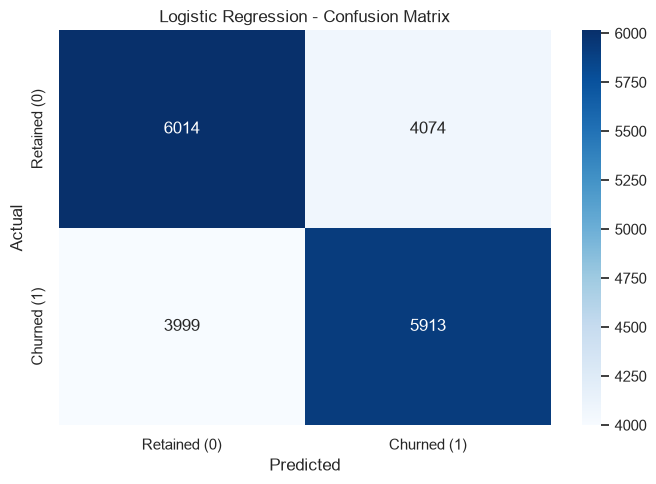

In [43]:
# Confusion matrix for Logistic Regression

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained (0)', 'Churned (1)'],
    yticklabels=['Retained (0)', 'Churned (1)']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

In [44]:
# Store baseline results for later comparison

model_results = []

model_results.append({
    'Model': 'Logistic Regression',
    **lr_results
})

print("Baseline results saved.")

Baseline results saved.


In [45]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [46]:
# Random Forest predictions

y_pred_rf = rf_model.predict(X_test_processed)
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

# Evaluation metrics
rf_results = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1 Score': f1_score(y_test, y_pred_rf),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf)
}

print("RANDOM FOREST - RESULTS")
print("=" * 45)

for metric, value in rf_results.items():
    print(f"{metric:<15}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

RANDOM FOREST - RESULTS
Accuracy       : 0.6193
Precision      : 0.6073
Recall         : 0.6564
F1 Score       : 0.6309
ROC-AUC        : 0.6724

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.58      0.61     10088
           1       0.61      0.66      0.63      9912

    accuracy                           0.62     20000
   macro avg       0.62      0.62      0.62     20000
weighted avg       0.62      0.62      0.62     20000



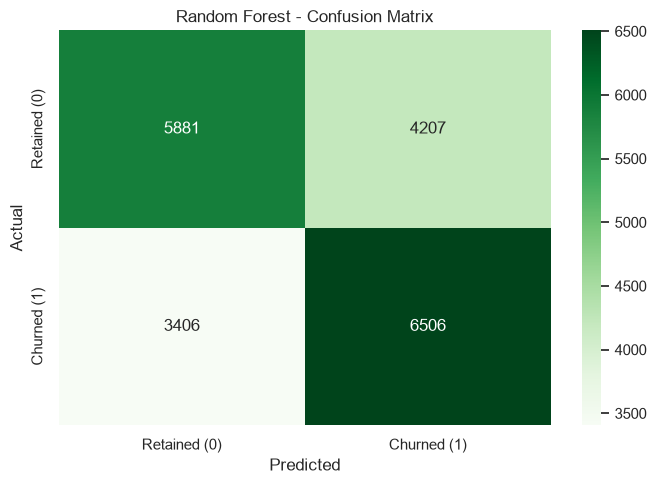

In [47]:
# Visualize Random Forest confusion matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Retained (0)', 'Churned (1)'],
    yticklabels=['Retained (0)', 'Churned (1)']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

In [48]:
model_results.append({
    'Model': 'Random Forest',
    **rf_results
})

print("Random Forest results saved.")

Random Forest results saved.


In [49]:
from sklearn.ensemble import ExtraTreesClassifier

extra_trees_model = ExtraTreesClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

extra_trees_model.fit(X_train_processed, y_train)

print("Extra Trees training completed!")

Extra Trees training completed!


In [50]:
# Extra Trees predictions

y_pred_et = extra_trees_model.predict(X_test_processed)
y_prob_et = extra_trees_model.predict_proba(X_test_processed)[:, 1]

# Evaluation metrics
et_results = {
    'Accuracy': accuracy_score(y_test, y_pred_et),
    'Precision': precision_score(y_test, y_pred_et),
    'Recall': recall_score(y_test, y_pred_et),
    'F1 Score': f1_score(y_test, y_pred_et),
    'ROC-AUC': roc_auc_score(y_test, y_prob_et)
}

print("EXTRA TREES - RESULTS")
print("=" * 45)

for metric, value in et_results.items():
    print(f"{metric:<15}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_et))

EXTRA TREES - RESULTS
Accuracy       : 0.5879
Precision      : 0.5839
Recall         : 0.5865
F1 Score       : 0.5852
ROC-AUC        : 0.6230

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.59      0.59     10088
           1       0.58      0.59      0.59      9912

    accuracy                           0.59     20000
   macro avg       0.59      0.59      0.59     20000
weighted avg       0.59      0.59      0.59     20000



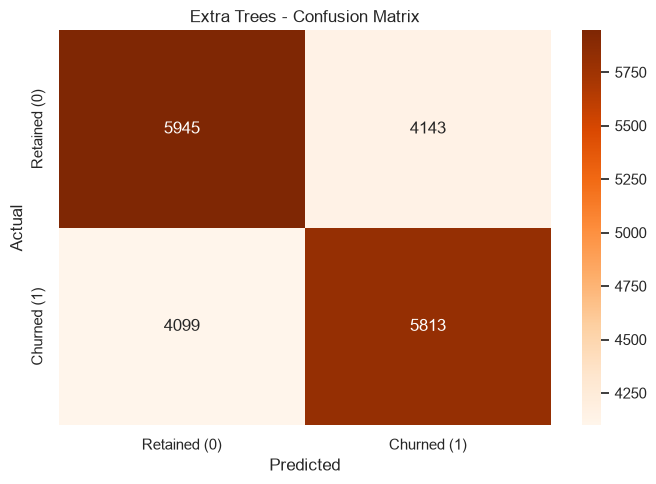

In [51]:
# Visualize Extra Trees confusion matrix

cm_et = confusion_matrix(y_test, y_pred_et)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_et,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Retained (0)', 'Churned (1)'],
    yticklabels=['Retained (0)', 'Churned (1)']
)

plt.title('Extra Trees - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

In [52]:
model_results.append({
    'Model': 'Extra Trees',
    **et_results
})

print("Extra Trees results saved.")

Extra Trees results saved.


In [53]:
# Compare all trained models

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")
print("=" * 70)

display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.62,0.61,0.66,0.63,0.67
1,Logistic Regression,0.60,0.59,0.60,0.59,0.63
2,Extra Trees,0.59,0.58,0.59,0.59,0.62


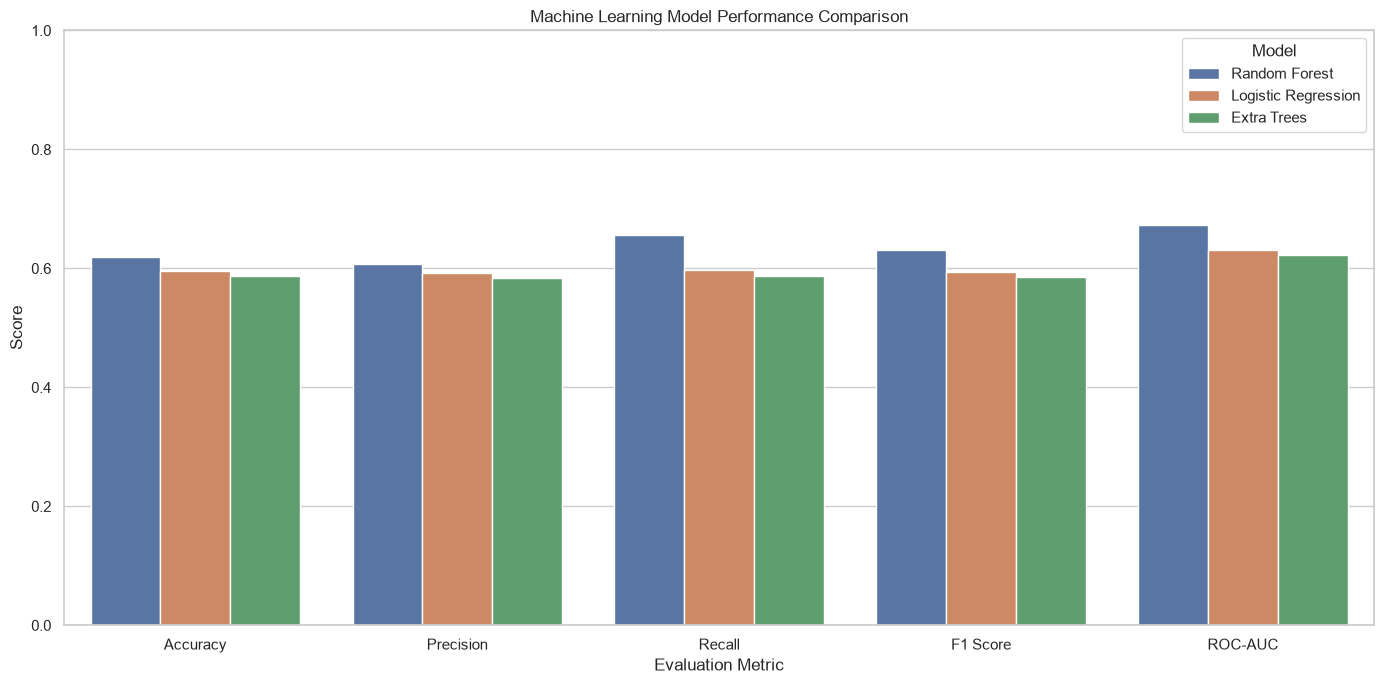

In [54]:
# Compare model metrics visually

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

results_melted = results_df.melt(
    id_vars='Model',
    value_vars=metrics_to_plot,
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=results_melted,
    x='Metric',
    y='Score',
    hue='Model'
)

plt.title('Machine Learning Model Performance Comparison')
plt.ylim(0, 1)
plt.ylabel('Score')
plt.xlabel('Evaluation Metric')
plt.legend(title='Model')
plt.tight_layout()
plt.show()

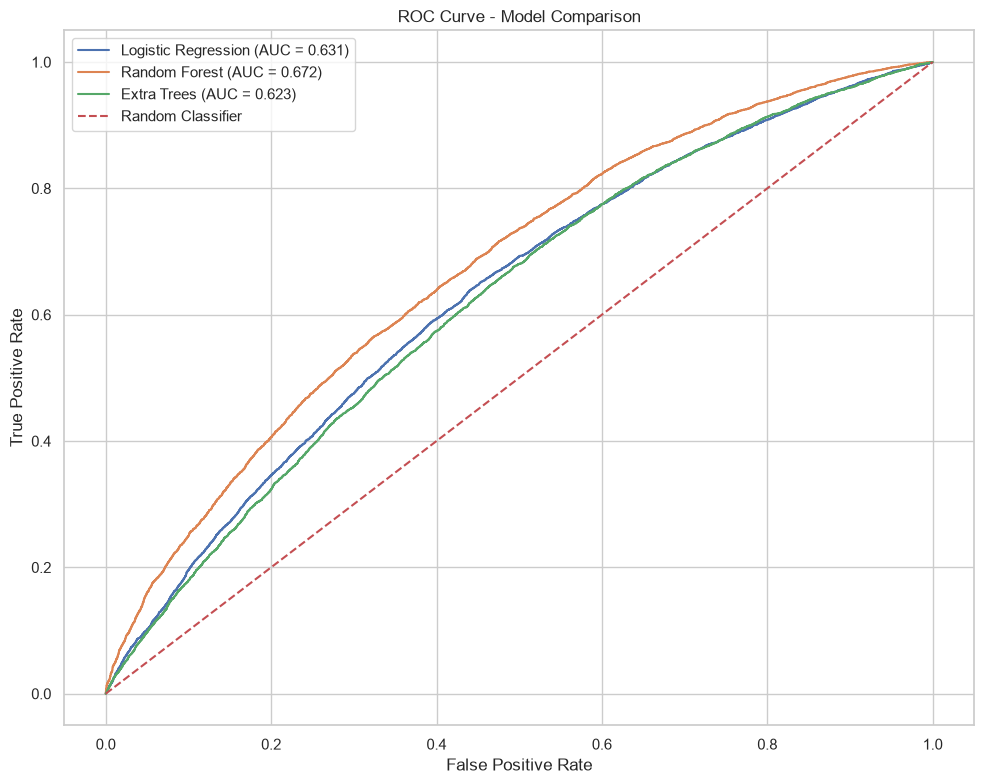

In [55]:
from sklearn.metrics import roc_curve

# Generate ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_et, tpr_et, _ = roc_curve(y_test, y_prob_et)

plt.figure(figsize=(10, 8))

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {lr_results["ROC-AUC"]:.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {rf_results["ROC-AUC"]:.3f})')
plt.plot(fpr_et, tpr_et, label=f'Extra Trees (AUC = {et_results["ROC-AUC"]:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Model Comparison')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [56]:
# Identify the best model based on ROC-AUC

best_model_name = results_df.iloc[0]['Model']
best_auc = results_df.iloc[0]['ROC-AUC']

print("BEST MODEL")
print("=" * 40)
print("Model:", best_model_name)
print(f"ROC-AUC: {best_auc:.4f}")

print("\nComplete ranking:")
display(results_df[['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']])

BEST MODEL
Model: Random Forest
ROC-AUC: 0.6724

Complete ranking:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.62,0.61,0.66,0.63,0.67
1,Logistic Regression,0.60,0.59,0.60,0.59,0.63
2,Extra Trees,0.59,0.58,0.59,0.59,0.62


In [57]:
# Save comparison results

RESULTS_DIR = Path("../outputs/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

print("Model comparison saved to:")
print(RESULTS_DIR / "model_comparison.csv")

Model comparison saved to:
../outputs/results/model_comparison.csv


In [58]:
# Select the best model based on ROC-AUC

trained_models = {
    'Logistic Regression': logistic_model,
    'Random Forest': rf_model,
    'Extra Trees': extra_trees_model
}

best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)
print("Best ROC-AUC:", round(best_auc, 4))

Selected model: Random Forest
Best ROC-AUC: 0.6724


In [59]:
# Extract feature importance from the selected model

if best_model_name in ['Random Forest', 'Extra Trees']:
    importance_values = best_model.feature_importances_

elif best_model_name == 'Logistic Regression':
    importance_values = np.abs(best_model.coef_[0])

feature_importance_df = pd.DataFrame({
    'Feature': processed_feature_names,
    'Importance': importance_values
})

feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("TOP 20 IMPORTANT FEATURES")
display(feature_importance_df.head(20).round(4))



TOP 20 IMPORTANT FEATURES


,Feature,Importance
0,num__eqpdays,0.06
1,num__months,0.05
2,num__change_mou,0.03
3,num__mou_Mean,0.02
4,num__adjrev,0.02
5,num__totmrc_Mean,0.02
6,num__totrev,0.02
7,num__avgqty,0.02
8,num__hnd_price,0.02
9,num__change_rev,0.02


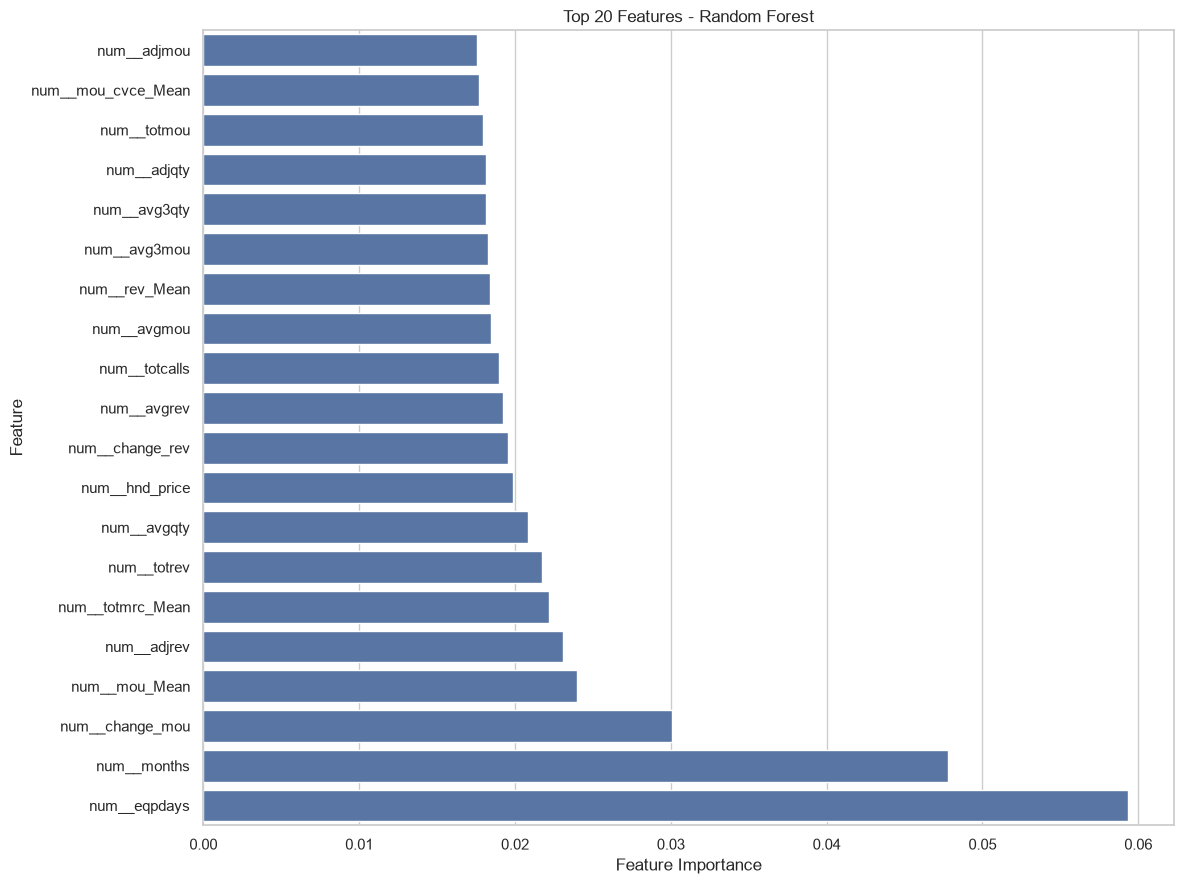

In [60]:
# Visualize the most influential features

top_features = feature_importance_df.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title(f'Top 20 Features - {best_model_name}')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [61]:
# Save feature importance to CSV

feature_importance_df.to_csv(
    RESULTS_DIR / 'feature_importance.csv',
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [62]:
# Predict churn probability for test customers

churn_probabilities = best_model.predict_proba(X_test_processed)[:, 1]

customer_risk_df = pd.DataFrame({
    'Customer_ID': df.loc[X_test.index, 'Customer_ID'].values,
    'Actual_Churn': y_test.values,
    'Churn_Probability': churn_probabilities
})

customer_risk_df['Risk_Level'] = pd.cut(
    customer_risk_df['Churn_Probability'],
    bins=[-0.01, 0.30, 0.60, 1.00],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

customer_risk_df = customer_risk_df.sort_values(
    by='Churn_Probability',
    ascending=False
).reset_index(drop=True)

display(customer_risk_df.head(10))

,Customer_ID,Actual_Churn,Churn_Probability,Risk_Level
0,1057208,1,0.91,High Risk
1,1001626,1,0.90,High Risk
2,1044532,1,0.90,High Risk
3,1034680,1,0.90,High Risk
4,1055965,1,0.90,High Risk
5,1083841,1,0.90,High Risk
6,1045781,1,0.89,High Risk
7,1056026,1,0.89,High Risk
8,1088435,1,0.89,High Risk
9,1034946,1,0.89,High Risk


CUSTOMER RISK DISTRIBUTION


Risk_Level
Low Risk        1014
Medium Risk    15879
High Risk       3107
Name: count, dtype: int64

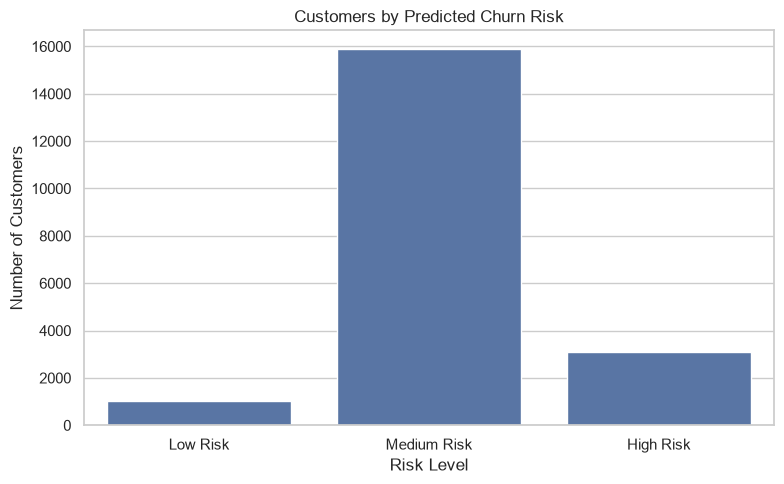

In [63]:
# Count customers in each risk category

risk_counts = customer_risk_df['Risk_Level'].value_counts().reindex(
    ['Low Risk', 'Medium Risk', 'High Risk']
)

print("CUSTOMER RISK DISTRIBUTION")
display(risk_counts)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=risk_counts.index,
    y=risk_counts.values
)

plt.title('Customers by Predicted Churn Risk')
plt.xlabel('Risk Level')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

In [64]:
# Evaluate actual churn within each risk group

risk_evaluation = customer_risk_df.groupby(
    'Risk_Level',
    observed=False
).agg(
    Customers=('Customer_ID', 'count'),
    Actual_Churners=('Actual_Churn', 'sum'),
    Actual_Churn_Rate=('Actual_Churn', 'mean'),
    Average_Predicted_Risk=('Churn_Probability', 'mean')
)

risk_evaluation['Actual_Churn_Rate'] *= 100
risk_evaluation['Average_Predicted_Risk'] *= 100

display(risk_evaluation.round(2))

,Customers,Actual_Churners,Actual_Churn_Rate,Average_Predicted_Risk
Risk_Level,,,,
Low Risk,1014,172,16.96,24.53
Medium Risk,15879,7504,47.26,48.49
High Risk,3107,2236,71.97,65.81


In [65]:
# Extract high-risk customers

high_risk_customers = customer_risk_df[
    customer_risk_df['Risk_Level'] == 'High Risk'
].copy()

high_risk_customers['Churn_Probability'] = (
    high_risk_customers['Churn_Probability'] * 100
)

high_risk_customers.to_csv(
    RESULTS_DIR / 'high_risk_customers.csv',
    index=False
)

print(f"High-risk customers identified: {len(high_risk_customers):,}")
print("High-risk customer list saved successfully!")

High-risk customers identified: 3,107
High-risk customer list saved successfully!


In [66]:
# Retention strategy framework

retention_strategy = pd.DataFrame({
    'Risk Level': ['High Risk', 'Medium Risk', 'Low Risk'],
    'Customer Profile': [
        'Customers with high predicted probability of churn',
        'Customers showing moderate churn risk',
        'Customers with low predicted probability of churn'
    ],
    'Recommended Action': [
        'Personalized retention offers, proactive calls, plan review, loyalty incentives',
        'Targeted engagement, usage monitoring, satisfaction surveys, relevant offers',
        'Loyalty rewards, engagement campaigns, cross-selling where appropriate'
    ],
    'Business Priority': [
        'Immediate intervention',
        'Preventive engagement',
        'Relationship strengthening'
    ]
})

display(retention_strategy)

,Risk Level,Customer Profile,Recommended Action,Business Priority
0,High Risk,Customers with high predicted probability of c...,"Personalized retention offers, proactive calls...",Immediate intervention
1,Medium Risk,Customers showing moderate churn risk,"Targeted engagement, usage monitoring, satisfa...",Preventive engagement
2,Low Risk,Customers with low predicted probability of churn,"Loyalty rewards, engagement campaigns, cross-s...",Relationship strengthening


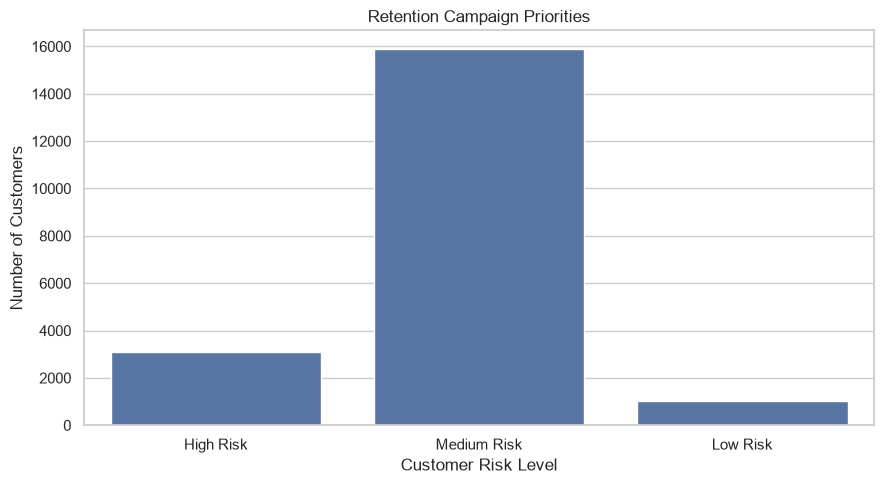

In [67]:
# Visual representation of the retention strategy

risk_order = ['High Risk', 'Medium Risk', 'Low Risk']

strategy_counts = customer_risk_df['Risk_Level'].value_counts().reindex(risk_order)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=strategy_counts.index,
    y=strategy_counts.values
)

plt.title('Retention Campaign Priorities')
plt.xlabel('Customer Risk Level')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

In [68]:
# Scenario-based retention impact analysis

high_risk_count = len(high_risk_customers)

# Assumptions - illustrative scenarios, not observed results
retention_success_rates = [0.05, 0.10, 0.15]

# Assumed average monthly revenue per customer
# Replace this with actual business data if available
assumed_monthly_revenue = 50

impact_scenarios = []

for success_rate in retention_success_rates:
    retained_customers = round(high_risk_count * success_rate)

    monthly_revenue_protected = (
        retained_customers * assumed_monthly_revenue
    )

    annual_revenue_protected = monthly_revenue_protected * 12

    impact_scenarios.append({
        'Retention Success Rate': f'{success_rate:.0%}',
        'Customers Retained (Estimated)': retained_customers,
        'Monthly Revenue Protected': monthly_revenue_protected,
        'Annual Revenue Protected': annual_revenue_protected
    })

impact_df = pd.DataFrame(impact_scenarios)

display(impact_df)

,Retention Success Rate,Customers Retained (Estimated),Monthly Revenue Protected,Annual Revenue Protected
0,5%,155,7750,93000
1,10%,311,15550,186600
2,15%,466,23300,279600


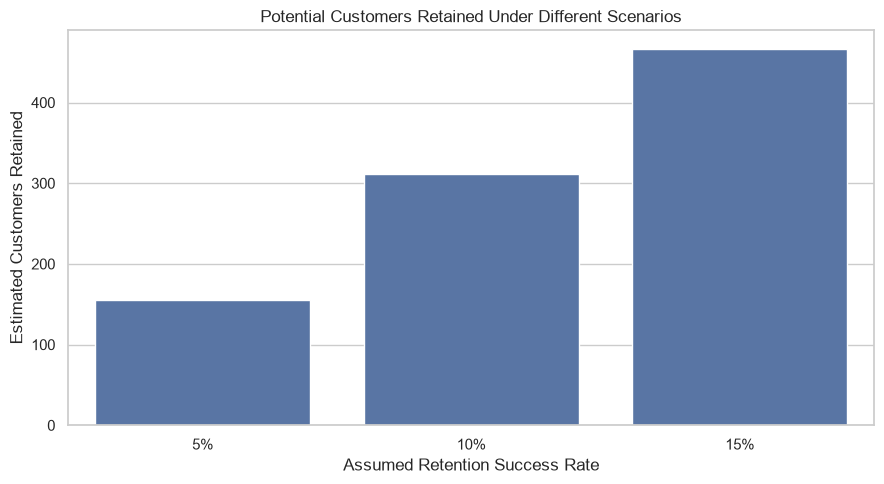

In [69]:
# Compare estimated retained customers across scenarios

plt.figure(figsize=(9, 5))

sns.barplot(
    data=impact_df,
    x='Retention Success Rate',
    y='Customers Retained (Estimated)'
)

plt.title('Potential Customers Retained Under Different Scenarios')
plt.xlabel('Assumed Retention Success Rate')
plt.ylabel('Estimated Customers Retained')
plt.tight_layout()
plt.show()

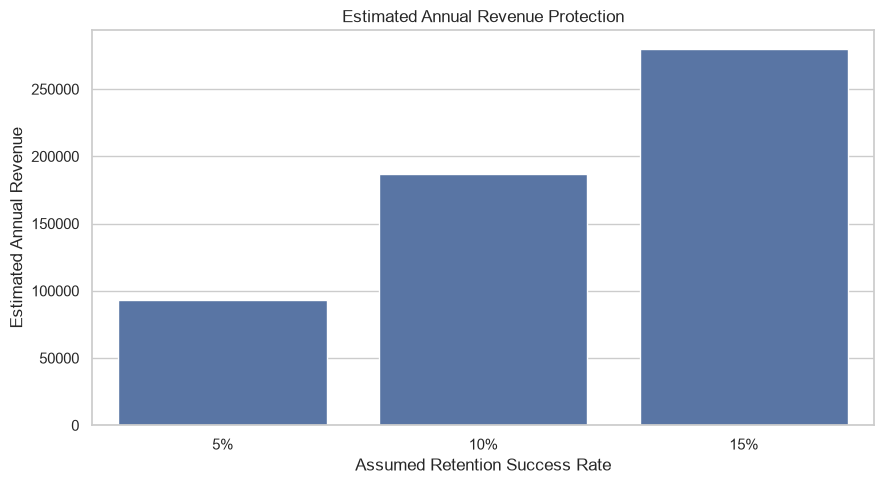

In [70]:
# Compare potential annual revenue protection

plt.figure(figsize=(9, 5))

sns.barplot(
    data=impact_df,
    x='Retention Success Rate',
    y='Annual Revenue Protected'
)

plt.title('Estimated Annual Revenue Protection')
plt.xlabel('Assumed Retention Success Rate')
plt.ylabel('Estimated Annual Revenue')
plt.tight_layout()
plt.show()

In [71]:
# Save business impact scenarios

impact_df.to_csv(
    RESULTS_DIR / 'business_impact_scenarios.csv',
    index=False
)

retention_strategy.to_csv(
    RESULTS_DIR / 'retention_strategy.csv',
    index=False
)

print("Business impact scenarios saved successfully!")

Business impact scenarios saved successfully!


In [72]:
display(results_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1 Score': '{:.4f}',
    'ROC-AUC': '{:.4f}'
}))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.6193,0.6073,0.6564,0.6309,0.6724
1,Logistic Regression,0.5964,0.5921,0.5965,0.5943,0.6310
2,Extra Trees,0.5879,0.5839,0.5865,0.5852,0.6230


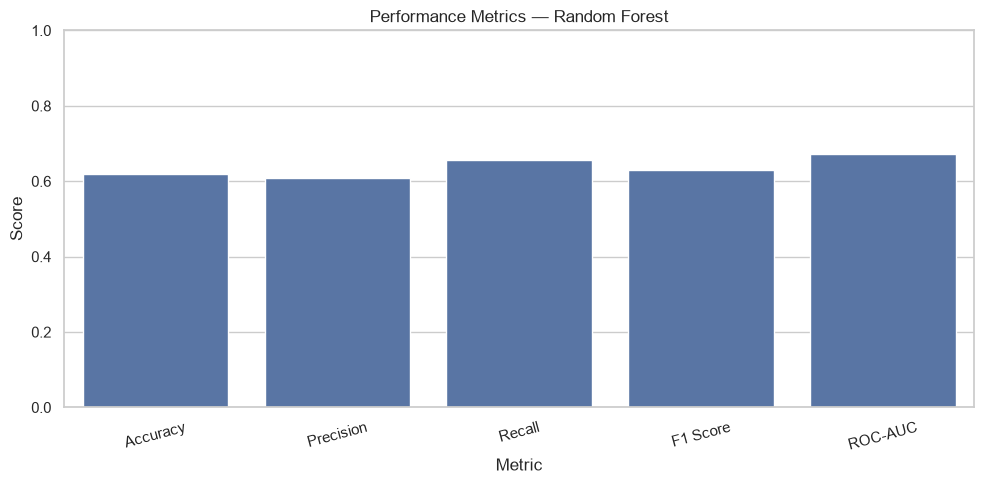

In [73]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

best_metrics = results_df[results_df['Model'] == best_model_name][metrics].iloc[0]

plt.figure(figsize=(10, 5))
sns.barplot(x=metrics, y=best_metrics.values)
plt.ylim(0, 1)
plt.title(f'Performance Metrics — {best_model_name}')
plt.ylabel('Score')
plt.xlabel('Metric')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [74]:
comparison_df = pd.DataFrame({
    'Actual Churn': y_test.values,
    'Predicted Churn': best_model.predict(X_test_processed)
})

comparison_df['Correct Prediction'] = (
    comparison_df['Actual Churn'] == comparison_df['Predicted Churn']
)

display(comparison_df.head(15))

,Actual Churn,Predicted Churn,Correct Prediction
0,1,1,True
1,0,1,False
2,0,0,True
3,1,0,False
4,0,0,True
5,0,1,False
6,0,1,False
7,0,1,False
8,0,1,False
9,1,0,False


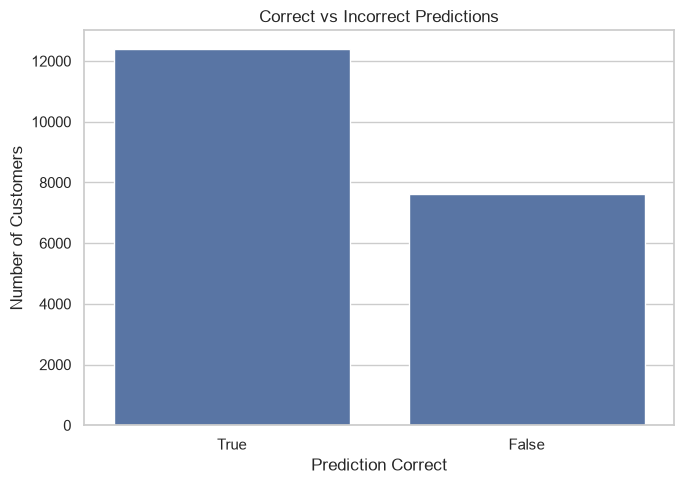

Correct predictions: 12,387
Incorrect predictions: 7,613
Overall accuracy: 61.93%


In [75]:
prediction_summary = comparison_df['Correct Prediction'].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(x=prediction_summary.index.astype(str), y=prediction_summary.values)
plt.title('Correct vs Incorrect Predictions')
plt.xlabel('Prediction Correct')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

print(f"Correct predictions: {comparison_df['Correct Prediction'].sum():,}")
print(f"Incorrect predictions: {(~comparison_df['Correct Prediction']).sum():,}")
print(f"Overall accuracy: {comparison_df['Correct Prediction'].mean():.2%}")

In [76]:
from sklearn.pipeline import Pipeline

final_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', best_model)
])

print("Final model pipeline created!")
print(f"Selected Model: {best_model_name}")

Final model pipeline created!
Selected Model: Random Forest


In [77]:
import joblib

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "telecom_churn_pipeline.pkl"

joblib.dump(final_pipeline, model_path)

print(f"Model saved to: {model_path}")

Model saved to: ../models/telecom_churn_pipeline.pkl


In [78]:
loaded_pipeline = joblib.load(model_path)

print("Model successfully loaded!")

Model successfully loaded!


In [79]:
saved_pipeline_predictions = loaded_pipeline.predict(X_test)

saved_pipeline_accuracy = accuracy_score(y_test, saved_pipeline_predictions)

print(f"Saved Pipeline Accuracy: {saved_pipeline_accuracy:.4f}")
print(f"Original Model Accuracy: {best_metrics['Accuracy']:.4f}")

assert np.array_equal(saved_pipeline_predictions, best_model.predict(X_test_processed)), \
    "Pipeline predictions do not match the original model!"

print("Pipeline verification successful!")

Saved Pipeline Accuracy: 0.6193
Original Model Accuracy: 0.6193
Pipeline verification successful!


In [80]:
final_report = {
    'Selected Model': best_model_name,
    'Accuracy': accuracy_score(y_test, saved_pipeline_predictions),
    'Precision': precision_score(y_test, saved_pipeline_predictions),
    'Recall': recall_score(y_test, saved_pipeline_predictions),
    'F1 Score': f1_score(y_test, saved_pipeline_predictions),
    'ROC-AUC': roc_auc_score(y_test, best_model.predict_proba(X_test_processed)[:, 1])
}

final_report_df = pd.DataFrame([final_report])

display(final_report_df)

final_report_df.to_csv(RESULTS_DIR / 'final_model_report.csv', index=False)

print("Final model report saved!")

,Selected Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.62,0.61,0.66,0.63,0.67


Final model report saved!


In [81]:
output_summary = pd.DataFrame({
    'Output File': [
        'model_comparison.csv',
        'feature_importance.csv',
        'high_risk_customers.csv',
        'business_impact_scenarios.csv',
        'retention_strategy.csv',
        'final_model_report.csv',
        'telecom_churn_pipeline.pkl'
    ],
    'Description': [
        'Comparison of all trained models',
        'Important features influencing model predictions',
        'Customers identified as high churn risk',
        'Estimated retention and revenue impact scenarios',
        'Recommended retention actions by risk category',
        'Final performance metrics of the selected model',
        'Saved preprocessing and prediction pipeline'
    ]
})

display(output_summary)

,Output File,Description
0,model_comparison.csv,Comparison of all trained models
1,feature_importance.csv,Important features influencing model predictions
2,high_risk_customers.csv,Customers identified as high churn risk
3,business_impact_scenarios.csv,Estimated retention and revenue impact scenarios
4,retention_strategy.csv,Recommended retention actions by risk category
5,final_model_report.csv,Final performance metrics of the selected model
6,telecom_churn_pipeline.pkl,Saved preprocessing and prediction pipeline


In [82]:
CHART_DIR = Path("../outputs/charts")
CHART_DIR.mkdir(parents=True, exist_ok=True)

def save_chart(filename):
    plt.savefig(
        CHART_DIR / filename,
        dpi=300,
        bbox_inches='tight',
        facecolor='white'
    )
    print(f"Saved: {filename}")

Saved: churn_distribution.png


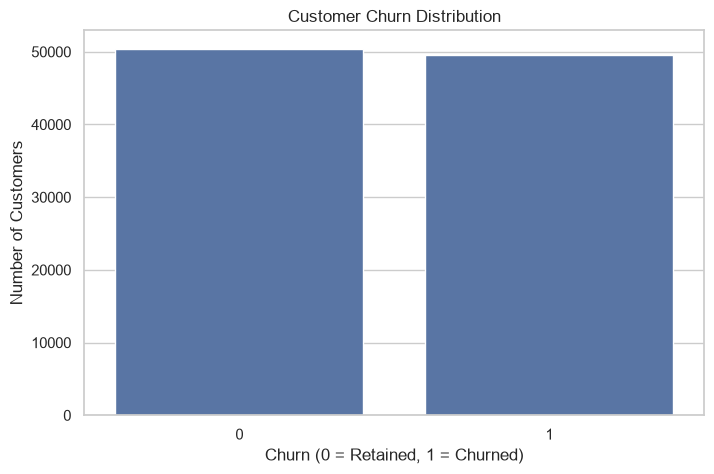

In [83]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn (0 = Retained, 1 = Churned)')
plt.ylabel('Number of Customers')

save_chart('churn_distribution.png')
plt.show()

Saved: top_15_features.png


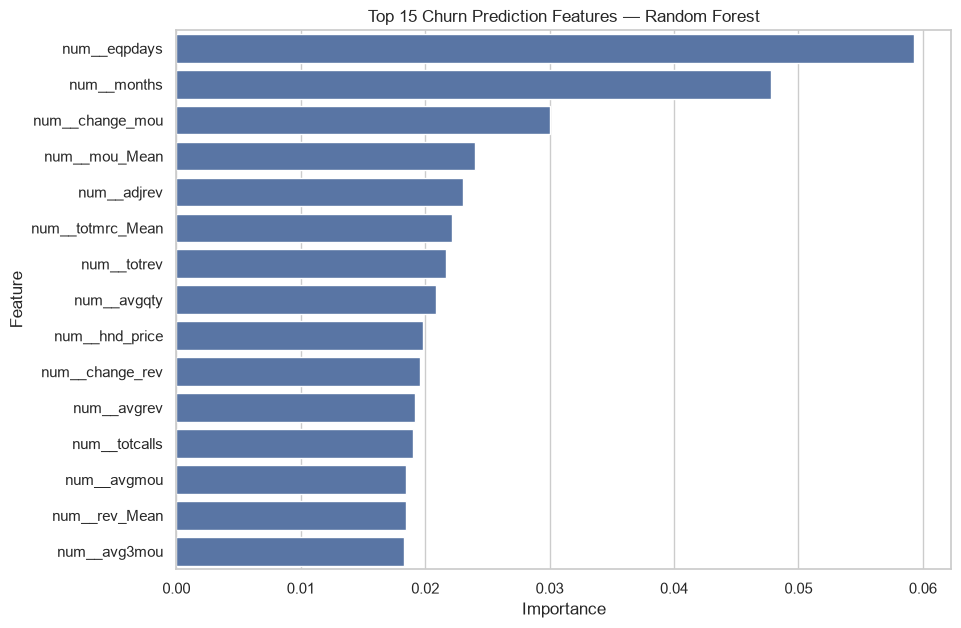

In [86]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title(f'Top 15 Churn Prediction Features — {best_model_name}')
plt.xlabel('Importance')
plt.ylabel('Feature')

save_chart('top_15_features.png')
plt.show()

Saved: final_model_roc_curve.png


<Figure size 800x600 with 0 Axes>

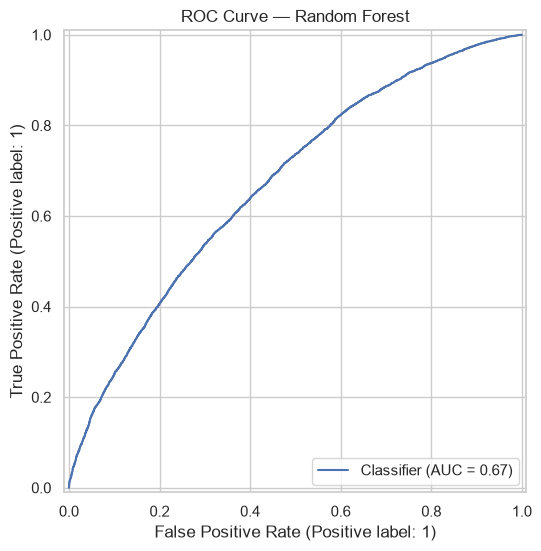

In [87]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    best_model.predict_proba(X_test_processed)[:, 1]
)

plt.title(f'ROC Curve — {best_model_name}')

save_chart('final_model_roc_curve.png')
plt.show()

Saved: final_confusion_matrix.png


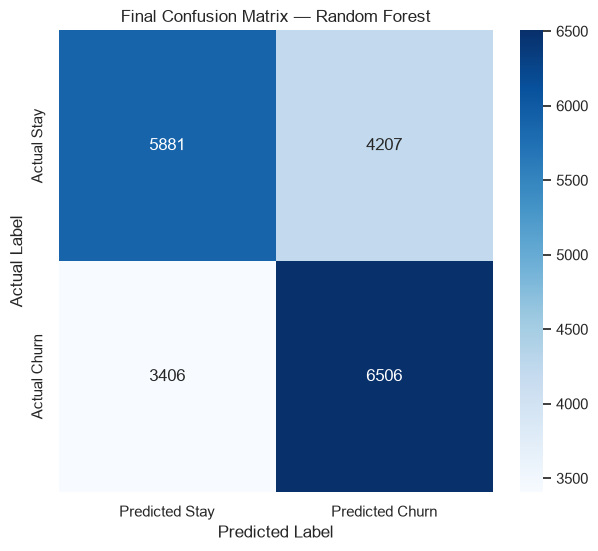

In [88]:
final_predictions = best_model.predict(X_test_processed)

cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted Stay', 'Predicted Churn'],
    yticklabels=['Actual Stay', 'Actual Churn']
)

plt.title(f'Final Confusion Matrix — {best_model_name}')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

save_chart('final_confusion_matrix.png')
plt.show()

In [89]:
print("=" * 60)
print("TELECOM CUSTOMER CHURN — PROJECT INSIGHTS")
print("=" * 60)

print(f"\nDataset size: {len(df):,} customers")
print(f"Churn rate: {df['churn'].mean():.2%}")
print(f"Selected model: {best_model_name}")
print(f"Model accuracy: {final_report['Accuracy']:.2%}")
print(f"Model ROC-AUC: {final_report['ROC-AUC']:.4f}")

print(f"\nHigh-risk customers identified: {len(high_risk_customers):,}")

print("\nTop 5 predictive features:")
display(feature_importance_df.head(5))

TELECOM CUSTOMER CHURN — PROJECT INSIGHTS

Dataset size: 100,000 customers
Churn rate: 49.56%
Selected model: Random Forest
Model accuracy: 61.93%
Model ROC-AUC: 0.6724

High-risk customers identified: 3,107

Top 5 predictive features:


,Feature,Importance
0,num__eqpdays,0.06
1,num__months,0.05
2,num__change_mou,0.03
3,num__mou_Mean,0.02
4,num__adjrev,0.02


In [90]:
print("BUSINESS RECOMMENDATIONS")
print("-" * 50)

print("""
1. HIGH-RISK CUSTOMERS
   Prioritize customers with the highest predicted churn probability.
   Use personalized offers, proactive support and plan reviews.

2. MEDIUM-RISK CUSTOMERS
   Conduct targeted engagement campaigns and monitor changes
   in customer usage and satisfaction.

3. LOW-RISK CUSTOMERS
   Strengthen loyalty through rewards, relevant service upgrades
   and positive customer experiences.

4. DATA-DRIVEN RETENTION
   Use churn predictions to allocate retention resources more
   efficiently rather than treating every customer identically.

5. CONTINUOUS MODEL IMPROVEMENT
   Retrain and monitor the model as customer behavior and
   telecom service conditions change.
""")

BUSINESS RECOMMENDATIONS
--------------------------------------------------

1. HIGH-RISK CUSTOMERS
   Prioritize customers with the highest predicted churn probability.
   Use personalized offers, proactive support and plan reviews.

2. MEDIUM-RISK CUSTOMERS
   Conduct targeted engagement campaigns and monitor changes
   in customer usage and satisfaction.

3. LOW-RISK CUSTOMERS
   Strengthen loyalty through rewards, relevant service upgrades
   and positive customer experiences.

4. DATA-DRIVEN RETENTION
   Use churn predictions to allocate retention resources more
   efficiently rather than treating every customer identically.

5. CONTINUOUS MODEL IMPROVEMENT
   Retrain and monitor the model as customer behavior and
   telecom service conditions change.



## Executive Summary

Customer churn is a significant business challenge for telecommunications companies, as losing customers can negatively affect recurring revenue, customer lifetime value, and long-term growth.

This project develops a data-driven customer churn prediction and retention framework using customer demographic, service, usage, billing, and behavioral information. The dataset is explored and prepared through data cleaning, missing-value treatment, feature preprocessing, and exploratory data analysis.

Multiple machine learning classification models are trained and evaluated using metrics including Accuracy, Precision, Recall, F1-score, and ROC-AUC. The best-performing model is selected to estimate churn probabilities and categorize customers into low-, medium-, and high-risk segments.

The proposed framework connects predictive analytics with practical retention strategies. By identifying customers at elevated risk of churn, Company A can prioritize targeted interventions, personalize retention campaigns, improve resource allocation, and potentially protect recurring revenue.

The project demonstrates how machine learning can support customer relationship management by transforming customer data into actionable business insights.

## Conclusion

This project demonstrates the application of machine learning to telecom customer churn prediction. Through exploratory data analysis, preprocessing, model comparison, and customer risk segmentation, a predictive framework was developed to identify customers who may be more likely to discontinue their services.

The final model provides churn probability estimates that can help the company distinguish customers by risk level and design appropriate retention strategies. These predictions can support more proactive customer engagement, targeted incentives, and improved retention planning.

While the model provides a foundation for data-driven decision-making, its effectiveness in a real business environment would depend on continuous monitoring, validation on future customer data, and evaluating the actual impact of retention campaigns.

Ultimately, the objective is not merely to predict customer churn, but to convert predictions into meaningful customer retention actions and sustainable business value.

In [91]:
summary_text = f"""
TELECOM CUSTOMER CHURN ANALYSIS
================================

Dataset:
- Total customers analyzed: {len(df):,}
- Churn rate: {df['churn'].mean():.2%}

Model:
- Selected model: {best_model_name}
- Accuracy: {final_report['Accuracy']:.4f}
- Precision: {final_report['Precision']:.4f}
- Recall: {final_report['Recall']:.4f}
- F1 Score: {final_report['F1 Score']:.4f}
- ROC-AUC: {final_report['ROC-AUC']:.4f}

High-Risk Customers:
- Identified: {len(high_risk_customers):,}

Business Objective:
Predict customer churn and support proactive customer retention
using machine learning and customer risk segmentation.

Recommended Strategy:
- Prioritize high-risk customers
- Deploy targeted retention campaigns
- Improve customer engagement
- Monitor model performance over time
- Evaluate retention campaign effectiveness
"""

summary_path = RESULTS_DIR / "project_summary.txt"

with open(summary_path, "w") as file:
    file.write(summary_text)

print(f"Project summary saved to: {summary_path}")

Project summary saved to: ../outputs/results/project_summary.txt


In [92]:
print("PROJECT FILE VERIFICATION")
print("=" * 50)

for folder in [CHART_DIR, RESULTS_DIR, MODEL_DIR]:
    print(f"\n📁 {folder.resolve()}")

    if folder.exists():
        for file in sorted(folder.iterdir()):
            if file.is_file():
                print(f"   ✓ {file.name}")
    else:
        print("   Folder does not exist!")

PROJECT FILE VERIFICATION

📁 /Users/sahilnabi/Desktop/Telecom_Churn_Analysis/outputs/charts
   ✓ churn_distribution.png
   ✓ final_confusion_matrix.png
   ✓ final_model_roc_curve.png
   ✓ top_15_features.png

📁 /Users/sahilnabi/Desktop/Telecom_Churn_Analysis/outputs/results
   ✓ business_impact_scenarios.csv
   ✓ feature_importance.csv
   ✓ final_model_report.csv
   ✓ high_risk_customers.csv
   ✓ model_comparison.csv
   ✓ project_summary.txt
   ✓ retention_strategy.csv

📁 /Users/sahilnabi/Desktop/Telecom_Churn_Analysis/models
   ✓ telecom_churn_pipeline.pkl
